In [2]:
%pip install matplotlib-label-lines

In [3]:
import os
import sys
import json
import traceback
from math import sqrt
import calendar
import pandas as pd
import numpy as np
from tqdm.auto import tqdm
from labellines import labelLine, labelLines
import xgboost
from sklearn.utils import shuffle
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import mean_absolute_percentage_error

In [4]:
import matplotlib.pyplot as plt
plt.style.library["seaborn-whitegrid"] = (
    plt.style.library["seaborn-v0_8-whitegrid"]
)

In [5]:
DATASET_NAME = 'open_source_ballarat_daily_waste_2000_jul_2015_mar'
DAILY_WASTE_DATA_FILE_PATH = f'/content/{DATASET_NAME}.csv'

PREPROCESSING_CACHE_DIR_PATH = '/content/preprocessing_cache'
os.makedirs(PREPROCESSING_CACHE_DIR_PATH, exist_ok=True)

In [6]:
print("Results folder:", PREPROCESSING_CACHE_DIR_PATH)

Results folder: /content/preprocessing_cache


Import datasets.

In [7]:
df = pd.read_csv("open_source_ballarat_daily_waste_2000_jul_2015_mar.csv")

In [8]:
df.head(5)

,ticket_date,net_weight_kg
0,2000-07-03,52380
1,2000-07-04,62940
2,2000-07-05,48260
3,2000-07-06,55580
4,2000-07-07,57800


In [9]:
df.shape

(3891, 2)

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3891 entries, 0 to 3890
Data columns (total 2 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   ticket_date    3891 non-null   object
 1   net_weight_kg  3891 non-null   int64 
dtypes: int64(1), object(1)
memory usage: 60.9+ KB


In [11]:
df.describe()

,net_weight_kg
count,3891.000000
mean,68949.877666
std,15111.891557
min,0.000000
25%,60160.000000
50%,67260.000000
75%,76530.000000
max,136000.000000


Check missing data

In [12]:
print(df['net_weight_kg'].isna().sum())

0


In [13]:
print(df['ticket_date'].duplicated().sum())


5


In [14]:
df['ticket_date'] = pd.to_datetime(df['ticket_date'])

In [15]:
print("Date range:")
print(df['ticket_date'].min(), "to", df['ticket_date'].max())

Date range:
2000-07-03 00:00:00 to 2015-03-27 00:00:00


In [16]:
expected_dates = pd.date_range(
    start=df['ticket_date'].min(),
    end=df['ticket_date'].max(),
    freq='D'
)

In [17]:
missing_dates = expected_dates.difference(df['ticket_date'])

In [18]:
print("Missing dates:", len(missing_dates))
print(missing_dates)

Missing dates: 1495
DatetimeIndex(['2000-07-08', '2000-07-09', '2000-07-15', '2000-07-16',
               '2000-07-22', '2000-07-23', '2000-07-29', '2000-07-30',
               '2000-08-05', '2000-08-06',
               ...
               '2015-01-25', '2015-02-01', '2015-02-08', '2015-02-15',
               '2015-02-22', '2015-03-01', '2015-03-08', '2015-03-11',
               '2015-03-15', '2015-03-22'],
              dtype='datetime64[ns]', length=1495, freq=None)


In [19]:
zero_count = (df['net_weight_kg'] == 0).sum()

print("Number of zero values:", zero_count)
print("Percentage of zero values:",
      zero_count / len(df) * 100, "%")

Number of zero values: 8
Percentage of zero values: 0.20560267283474687 %


checking outliers

In [20]:
Q1 = df['net_weight_kg'].quantile(0.25)
Q3 = df['net_weight_kg'].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

outliers = df[
    (df['net_weight_kg'] < lower_limit) |
    (df['net_weight_kg'] > upper_limit)
]

print("Lower limit:", lower_limit)
print("Upper limit:", upper_limit)
print("Number of potential outliers:", len(outliers))

print(outliers[['ticket_date', 'net_weight_kg']])

Lower limit: 35605.0
Upper limit: 101085.0
Number of potential outliers: 171
     ticket_date  net_weight_kg
818   2003-08-25          33440
1129  2004-11-02         105460
1159  2004-12-14         105420
2320  2009-05-27          34080
2488  2010-01-18              0
...          ...            ...
3862  2015-02-21           4620
3868  2015-02-28          11240
3874  2015-03-07          10900
3879  2015-03-14          14060
3885  2015-03-21           9080

[171 rows x 2 columns]


In [21]:
daily_df = (
    df.groupby('ticket_date', as_index=False)['net_weight_kg']
    .sum()
)

daily_df['day_of_week'] = daily_df['ticket_date'].dt.day_name()
daily_df['month'] = daily_df['ticket_date'].dt.month
daily_df['year'] = daily_df['ticket_date'].dt.year

In [22]:
#Average waste by day of the week
weekday_avg = daily_df.groupby(
    'day_of_week'
)['net_weight_kg'].mean()

print(weekday_avg)

day_of_week
Friday       72120.659631
Monday       67676.921053
Saturday     30667.529412
Thursday     65620.359580
Tuesday      81739.315789
Wednesday    62353.114323
Name: net_weight_kg, dtype: float64


In [23]:
#average waste by month
monthly_avg = daily_df.groupby(
    'month'
)['net_weight_kg'].mean()

print(monthly_avg)

month
1     69420.925373
2     69838.090615
3     67868.502994
4     67021.485149
5     66065.316456
6     64922.019868
7     64806.231454
8     66273.550296
9     70824.906832
10    72963.909366
11    74363.938462
12    73725.149701
Name: net_weight_kg, dtype: float64


Preprocess datasets.

In [24]:
# Get the year.
df['year'] = pd.DatetimeIndex(df['ticket_date']).year

In [25]:
# Get the month.
df['month'] = pd.DatetimeIndex(df['ticket_date']).month

In [26]:
df.columns

Index(['ticket_date', 'net_weight_kg', 'year', 'month'], dtype='object')

###Filter the `ticket_date` and `net_weight_kg` columns.

In [27]:
df = df[['ticket_date', 'net_weight_kg']].groupby(['ticket_date']).agg('sum').reset_index()

### Convert `ticket_date` to UTC.

In [28]:
df['ticket_date'] = pd.to_datetime(df['ticket_date'], utc=True)

###Convert `net_waste_kg` to numeric.

In [29]:
df['net_weight_kg'] = pd.to_numeric(df['net_weight_kg'])

###Keep the dates between `2001-01-01` and `2011-12-31`.

In [30]:
date_range_df = pd.date_range(start="2001-01-01", end="2011-12-31").to_frame(index=False, name='ticket_date')
date_range_df['ticket_date'] = pd.to_datetime(date_range_df['ticket_date'], utc=True)

### Add the complete date range to the `df`.

In [31]:
df = pd.merge(left=date_range_df, right=df, how='left', left_on='ticket_date', right_on='ticket_date')

###Set Saturdays and Sundays to 0

In [32]:
df['net_weight_kg'].loc[(df['ticket_date'].dt.dayofweek == 5) | (df['ticket_date'].dt.dayofweek == 6)] = 0

/tmp/ipykernel_33220/2056337439.py:1: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  df['net_weight_kg'].loc[(df['ticket_date'].dt.dayofweek == 5) | (df['ticket_date'].dt.dayofweek == 6)] = 0
/tmp/ipykernel_33220/2056337439.py:1: SettingWithC

### Available values

In [33]:
print(f'Available values: {df["net_weight_kg"].count()}')

Available values: 3991


###Missing values in net_weight_kg

In [34]:
missing_value_count = df["net_weight_kg"].isna().sum()
print(f'# missing values: {missing_value_count}')

# missing values: 26


In [35]:
df.isnull().sum()

,0
ticket_date,0
net_weight_kg,26


In [36]:
# df['net_weight_kg'] = df['net_weight_kg'].interpolate(method='linear', limit_direction='both')
df = df.fillna(-100000)

In [37]:
df.isnull().sum()

,0
ticket_date,0
net_weight_kg,0


In [38]:
df = df.set_index('ticket_date')

In [39]:
%pip install adtk

In [40]:
from adtk.data import validate_series
df = validate_series(df)
display(df)

,net_weight_kg
ticket_date,
2001-01-01 00:00:00+00:00,-100000.0
2001-01-02 00:00:00+00:00,61620.0
2001-01-03 00:00:00+00:00,71040.0
2001-01-04 00:00:00+00:00,55570.0
2001-01-05 00:00:00+00:00,59320.0
...,...
2011-12-27 00:00:00+00:00,72160.0
2011-12-28 00:00:00+00:00,78360.0
2011-12-29 00:00:00+00:00,76500.0


[<Axes: >]

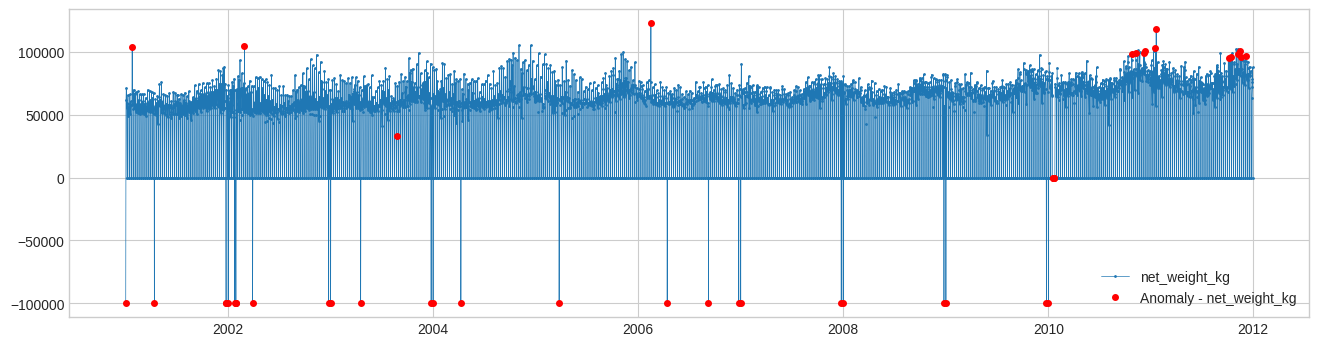

In [41]:
from adtk.detector import SeasonalAD
from adtk.visualization import plot

# Create the seasonal anomaly detector
seasonal_ad = SeasonalAD()

# Detect anomalies in the time-series data
anomalies = seasonal_ad.fit_detect(df)

# Plot the original data and highlight anomalies
plot(
    df,
    anomaly=anomalies,
    anomaly_color="red",
    anomaly_tag="marker"
)

Remove outliers

In [42]:
anomalies_mask = np.array(anomalies.reset_index()['net_weight_kg'].tolist())

In [43]:
print(f'outliers: {anomalies_mask.sum() - missing_value_count}')

outliers: 21


In [44]:
df['net_weight_kg'] = df['net_weight_kg'].iloc[~anomalies_mask]

In [45]:
df = df.reset_index()

Set (Saturdays, Sundays) detected as outliers to 0

In [46]:
df['net_weight_kg'].loc[(df['ticket_date'].dt.dayofweek == 5) | (df['ticket_date'].dt.dayofweek == 6)] = 0

/tmp/ipykernel_33220/2056337439.py:1: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  df['net_weight_kg'].loc[(df['ticket_date'].dt.dayofweek == 5) | (df['ticket_date'].dt.dayofweek == 6)] = 0
/tmp/ipykernel_33220/2056337439.py:1: SettingWithC

Set value for `2001-01-01` (Monday)

In [47]:
df.at[0, 'net_weight_kg'] = df.head(5)['net_weight_kg'].mean()

In [48]:
df.head(5)

,ticket_date,net_weight_kg
0,2001-01-01 00:00:00+00:00,61887.5
1,2001-01-02 00:00:00+00:00,61620.0
2,2001-01-03 00:00:00+00:00,71040.0
3,2001-01-04 00:00:00+00:00,55570.0
4,2001-01-05 00:00:00+00:00,59320.0


### Waste Data Visualization

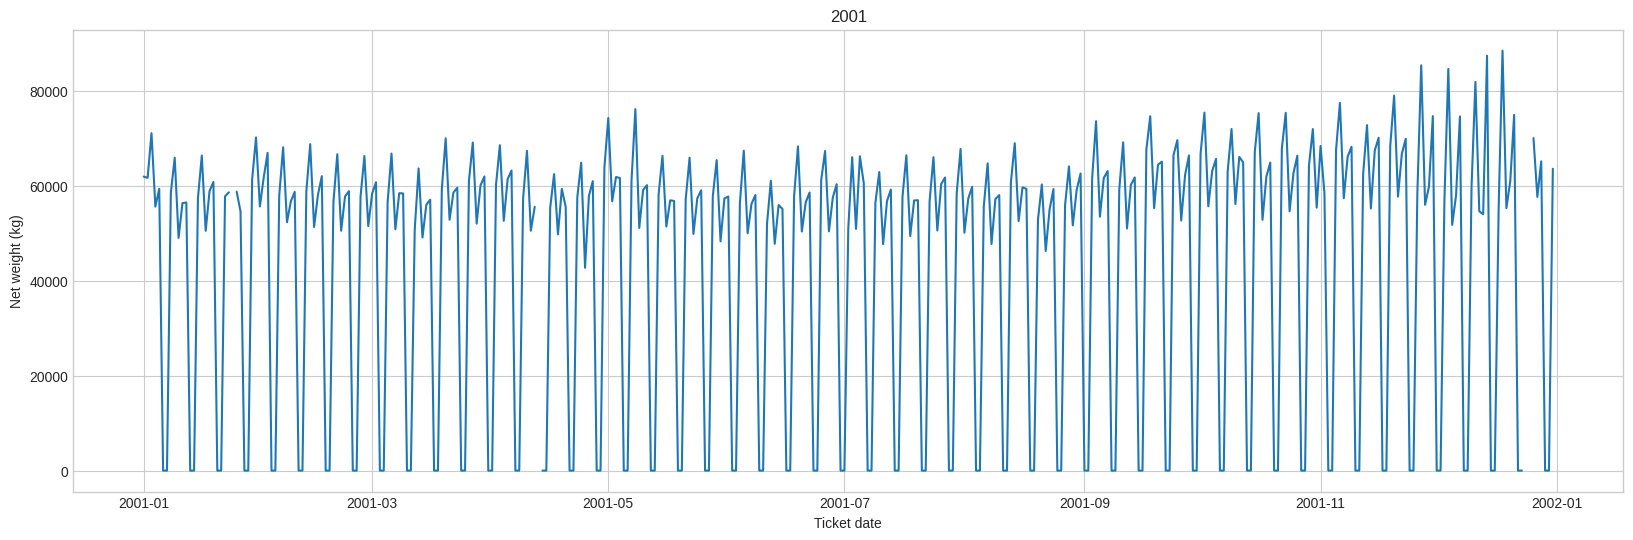

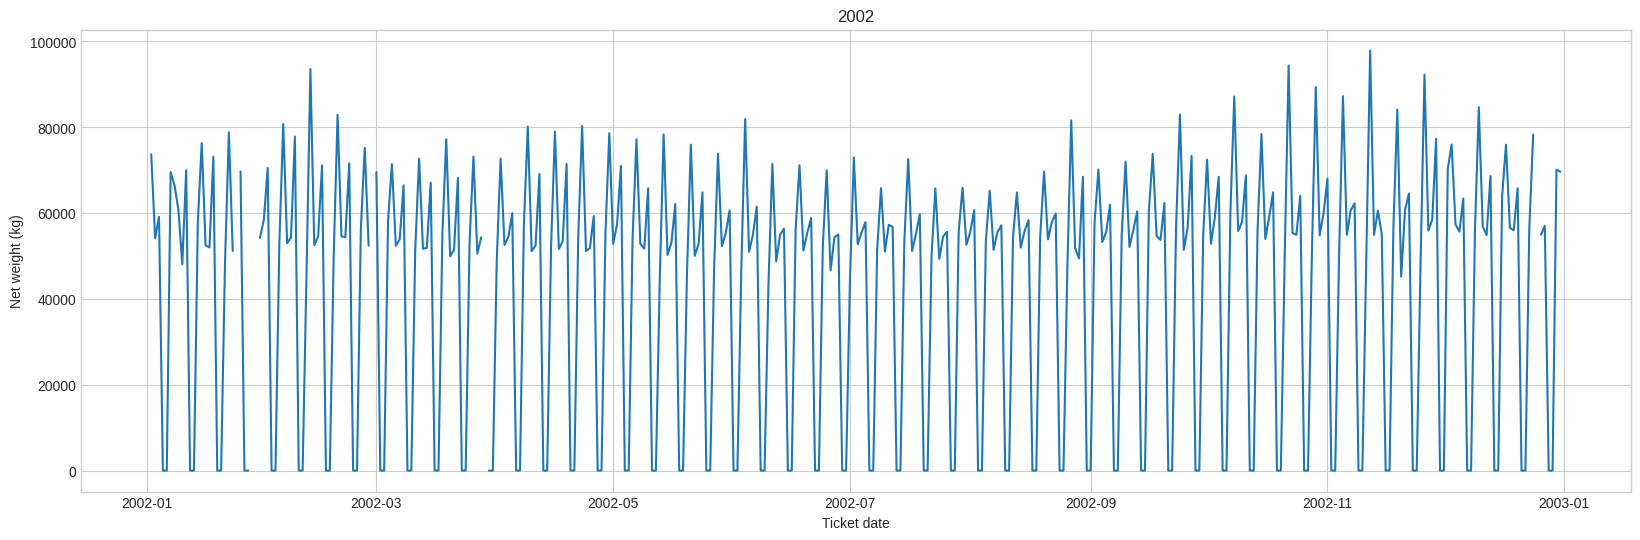

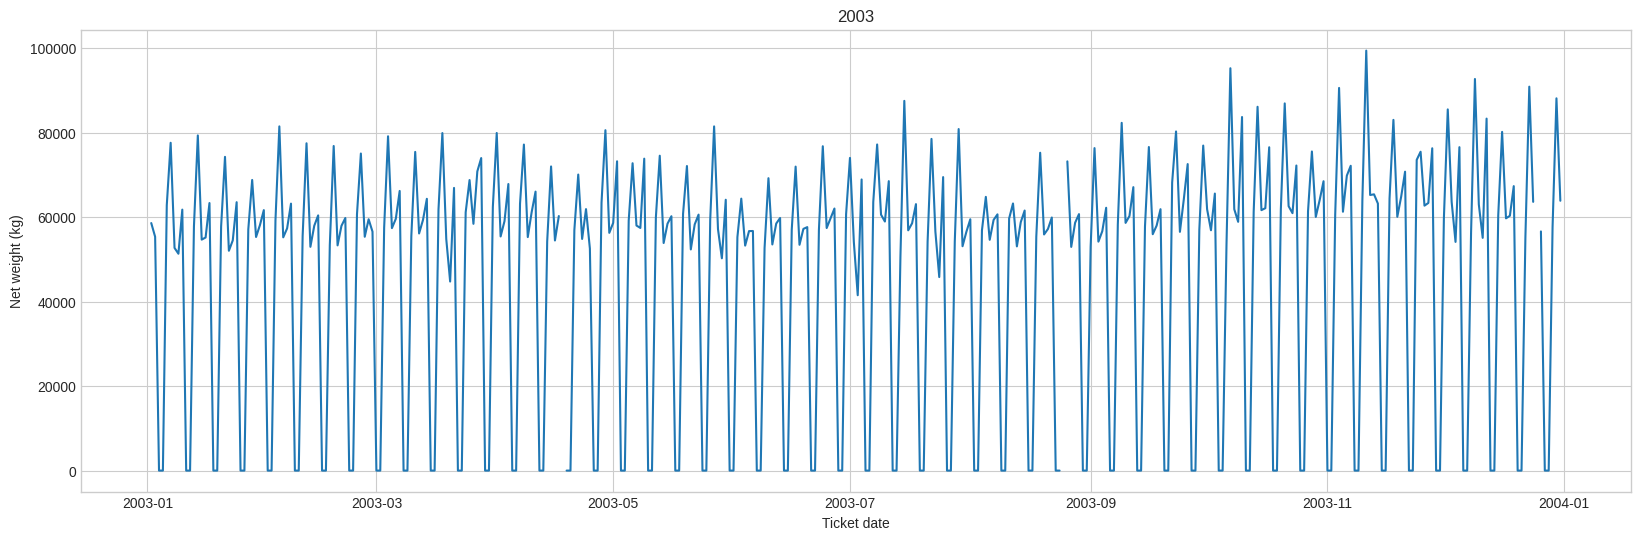

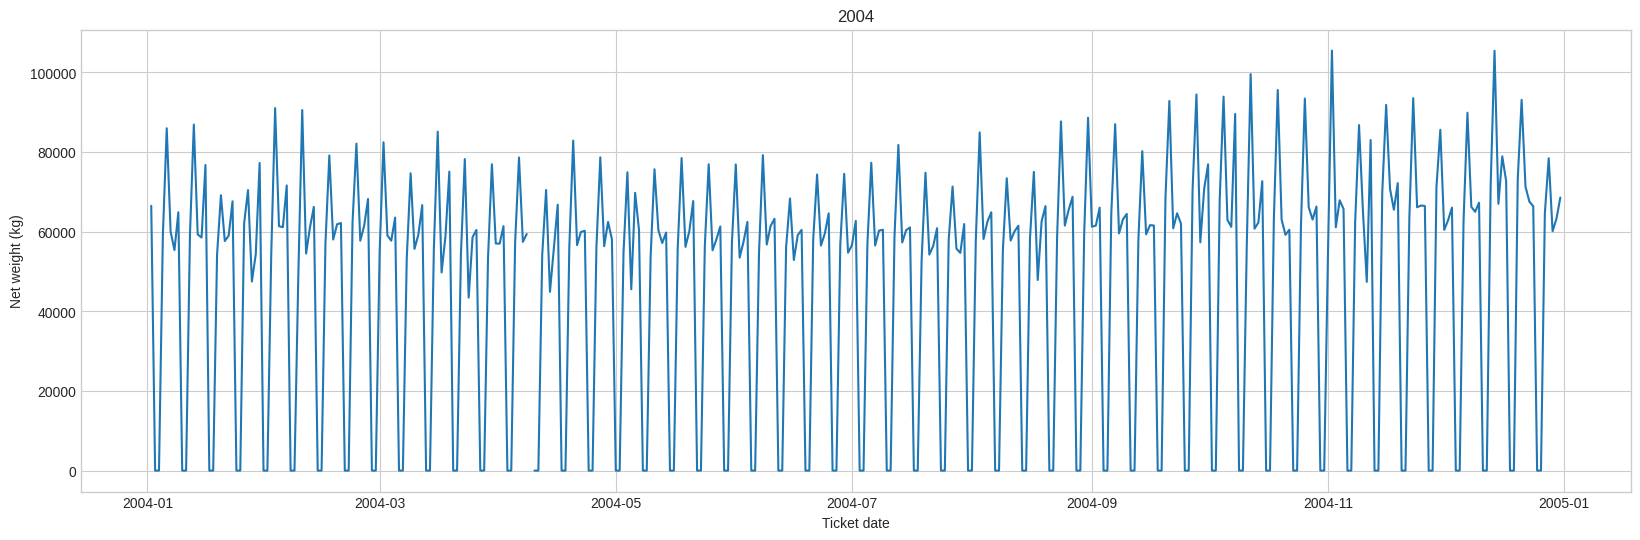

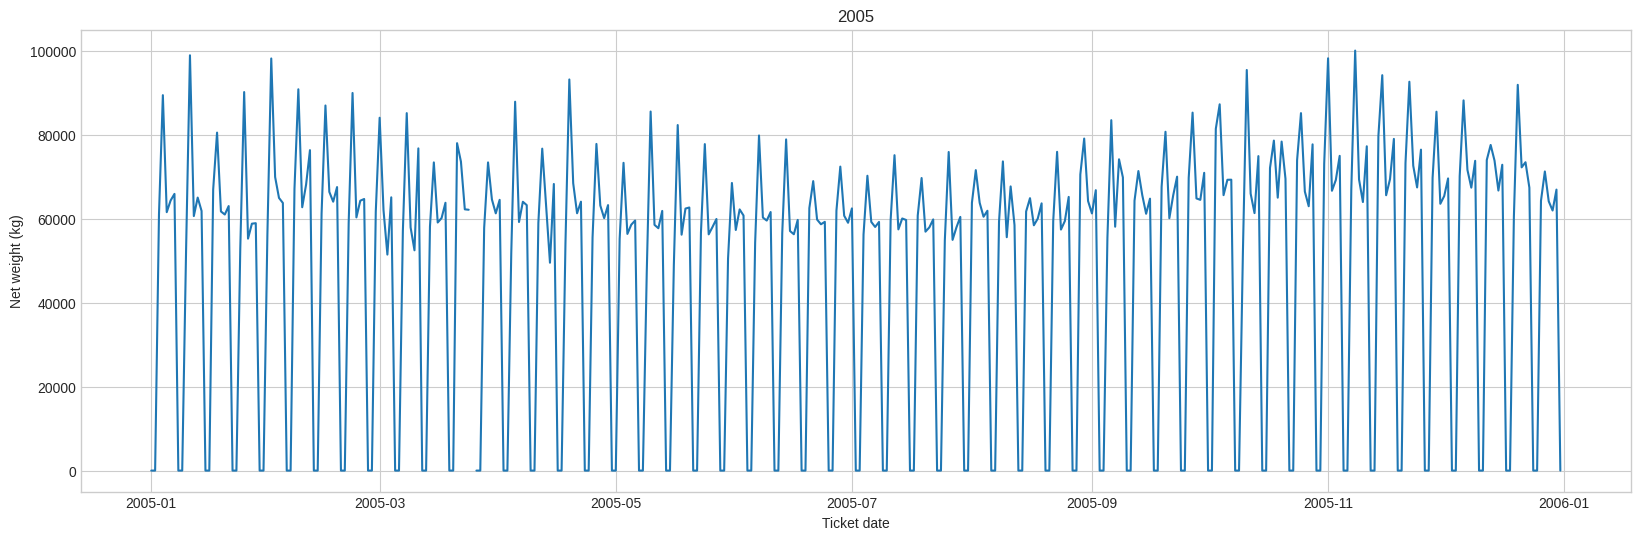

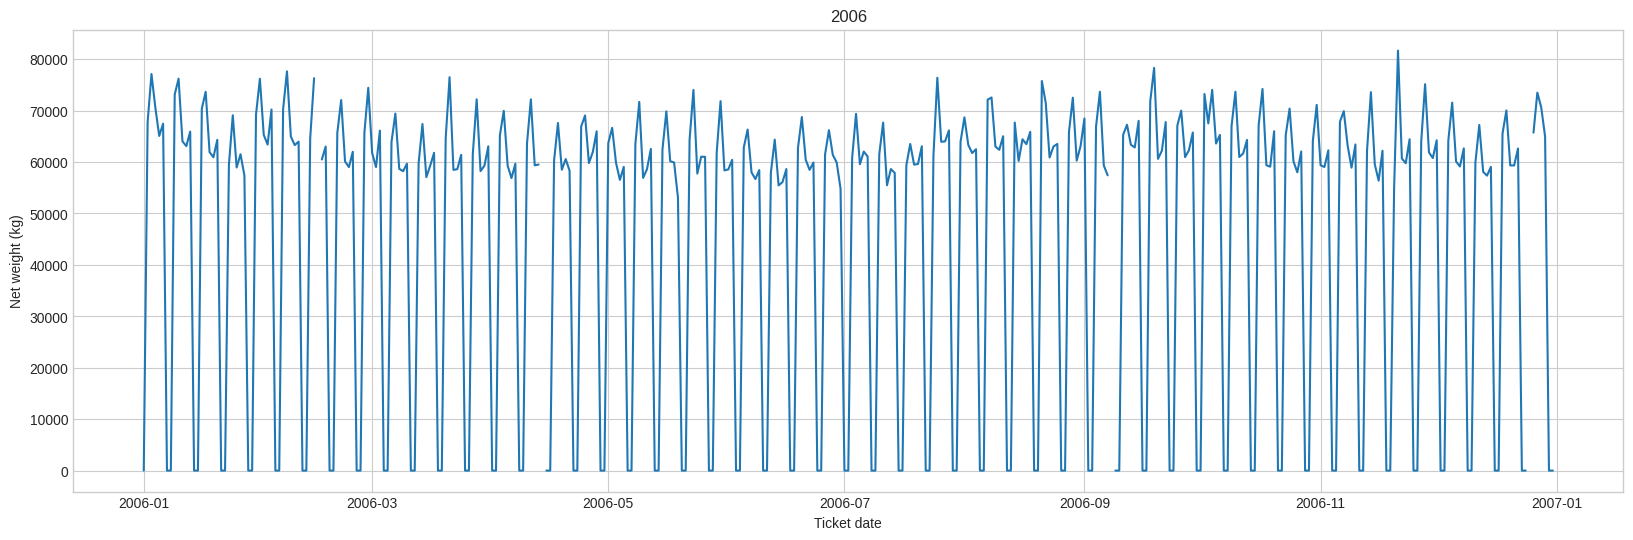

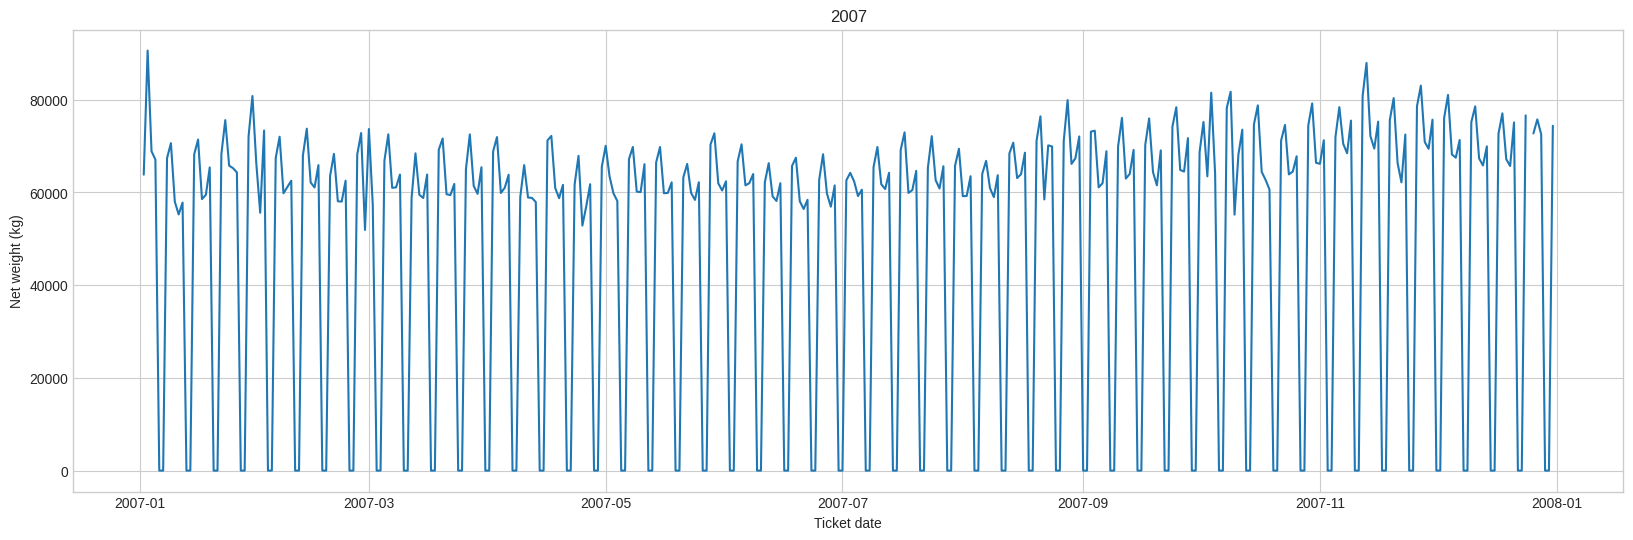

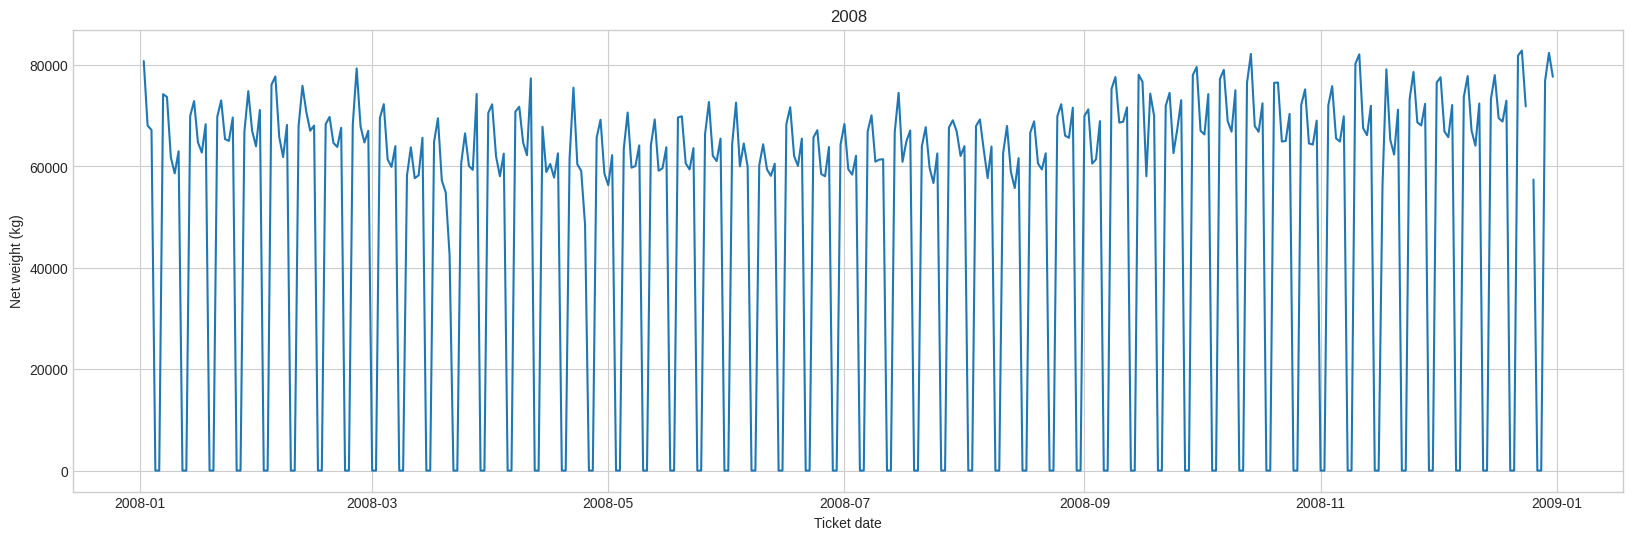

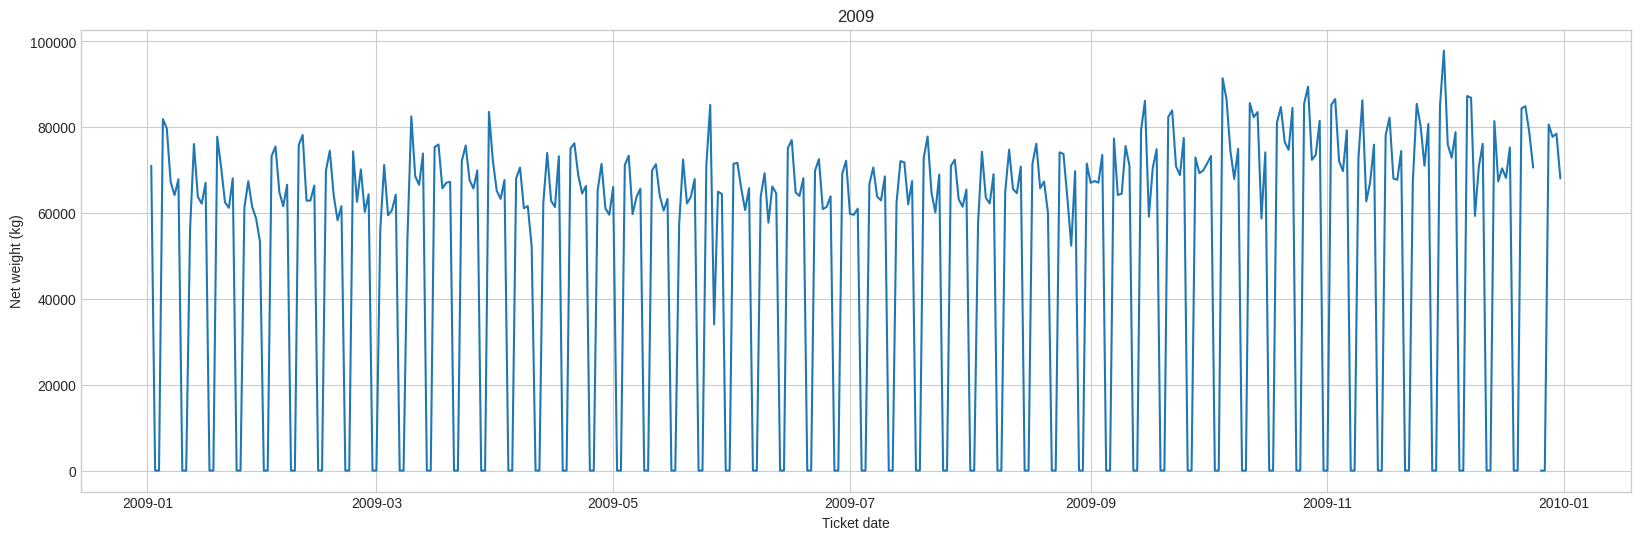

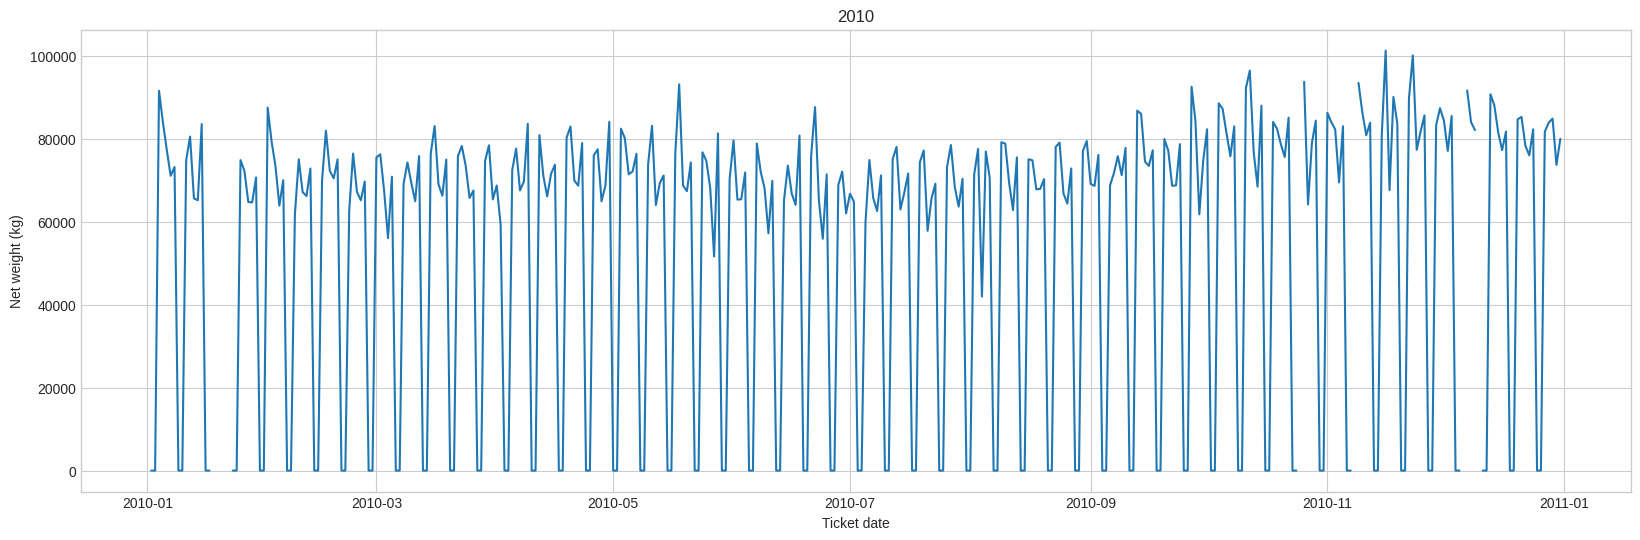

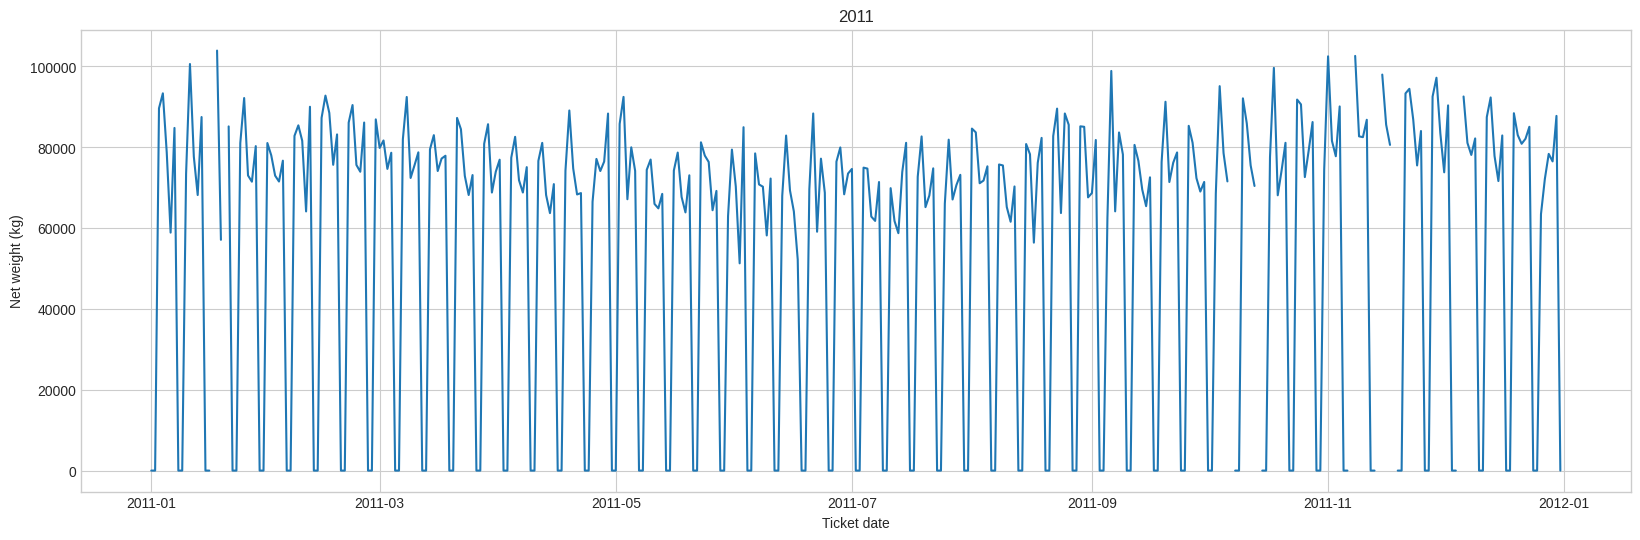

In [49]:
for year in range(2001, 2012):
    x = df[df['ticket_date'].dt.year == year]['ticket_date'].tolist()
    y = df[df['ticket_date'].dt.year == year]['net_weight_kg'].tolist()

    plt.rcParams['figure.dpi'] = 100
    plt.rcParams["figure.figsize"] = (20, 6)

    plt.plot(x, y)
    plt.title('{}'.format(year))
    plt.xlabel('Ticket date')
    plt.ylabel('Net weight (kg)')
    plt.show()

### best model selection

Hyperparameter tuning for XGBoost

In [50]:
# lag_count_list = [
#     1, 2, 3, 4, 5, 6, 7,
#     14, 21, 28, 35, 42, 49, 56,
#     30, 60, 90, 120, 150, 180, 360
# ]

# estimator_count_list = [10, 100, 1000]
# max_depth_list = [3, 4, 5, 6, 7, 8, 9]
# subsample_list = [0.5, 0.6, 0.7, 0.8, 0.9]
# eta_list = [0.001, 0.01, 0.1, 0.2, 0.3]

# n_iter = (
#     len(lag_count_list)
#     * len(estimator_count_list)
#     * len(max_depth_list)
#     * len(subsample_list)
#     * len(eta_list)
# )

# print("Total configurations:", n_iter)

In [51]:
lag_count_list = [42, 14]

estimator_count_list = [1000]

max_depth_list = [7, 4]

subsample_list = [0.6]

eta_list = [0.01]

# Calculate total configurations
n_iter = (
    len(lag_count_list)
    * len(estimator_count_list)
    * len(max_depth_list)
    * len(subsample_list)
    * len(eta_list)
)

print("Total configurations:", n_iter)

Total configurations: 4


In [52]:
def evaluate(lag_count, estimator_count, max_depth, subsample, eta):

    df_temp = df.copy()

    # Create lag features from previous days
    for i in range(1, lag_count + 1):
        df_temp[f'net_weight_kg_lag_{i}'] = (
            df_temp['net_weight_kg'].shift(i)
        )

    # Remove rows missing the target or required lag values
    lag_columns = [
        f'net_weight_kg_lag_{i}'
        for i in range(1, lag_count + 1)
    ]

    df_temp = df_temp.dropna(
        subset=['net_weight_kg'] + lag_columns
    )

    # Separate features and target
    X = df_temp.drop(columns=['ticket_date', 'net_weight_kg'])
    y = df_temp['net_weight_kg']

    # Split chronologically: first 80% for training, last 20% for testing
    split_index = int(len(df_temp) * 0.8)

    X_train, X_test = X.iloc[:split_index], X.iloc[split_index:]
    y_train, y_test = y.iloc[:split_index], y.iloc[split_index:]

    model = xgboost.XGBRegressor(
        n_estimators=estimator_count,
        random_state=0,
        max_depth=max_depth,
        subsample=subsample,
        learning_rate=eta,
        objective='reg:squarederror',
        n_jobs=-1
    )

    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    rmse = sqrt(mean_squared_error(y_test, y_pred))

    return rmse

In [53]:
# test_rmse = evaluate(
#     lag_count=7,
#     estimator_count=10,
#     max_depth=3,
#     subsample=0.8,
#     eta=0.1
# )

# print("Test RMSE:", test_rmse)

In [54]:
results = []
errors = []

with tqdm(total=n_iter, desc="Grid Search") as pbar:

    for lag_count in lag_count_list:
        for estimator_count in estimator_count_list:
            for max_depth in max_depth_list:
                for subsample in subsample_list:
                    for eta in eta_list:

                        filename = (
                            f'lag-{lag_count}'
                            f'_est-{estimator_count}'
                            f'_dpt-{max_depth}'
                            f'_subsmp-{subsample}'
                            f'_eta-{eta}.json'
                        )

                        file_path = os.path.join(
                            PREPROCESSING_CACHE_DIR_PATH,
                            filename
                        )

                        try:
                            if os.path.exists(file_path):
                                with open(file_path, 'r') as f:
                                    summary = json.load(f)
                            else:
                                rmse = evaluate(
                                    lag_count,
                                    estimator_count,
                                    max_depth,
                                    subsample,
                                    eta
                                )

                                summary = {
                                    'rmse': float(rmse),
                                    'lag_count': lag_count,
                                    'estimator_count': estimator_count,
                                    'max_depth': max_depth,
                                    'subsample': subsample,
                                    'eta': eta
                                }

                                with open(file_path, 'w') as f:
                                    json.dump(summary, f, indent=4)

                            results.append(summary)

                        except Exception as e:
                            errors.append({
                                'filename': filename,
                                'error': str(e)
                            })

                        finally:
                            pbar.update(1)

print("Completed.")
print("Successful results:", len(results))
print("Failed configurations:", len(errors))

Grid Search:   0%|          | 0/4 [00:00<?, ?it/s]

Completed.
Successful results: 4
Failed configurations: 0


In [55]:
if results:
    results_df = pd.DataFrame(results)

    results_df = results_df.sort_values(
        'rmse'
    ).reset_index(drop=True)

    display(results_df.head(10))

    print("Best configuration:")
    display(results_df.iloc[[0]])

    results_df.to_csv(
        '/content/preprocessing_cache/all_grid_search_results.csv',
        index=False
    )

,rmse,lag_count,estimator_count,max_depth,subsample,eta
0,5629.160772,42,1000,4,0.6,0.01
1,6076.585807,14,1000,4,0.6,0.01
2,6336.546008,42,1000,7,0.6,0.01
3,6622.510572,14,1000,7,0.6,0.01


Best configuration:


,rmse,lag_count,estimator_count,max_depth,subsample,eta
0,5629.160772,42,1000,4,0.6,0.01


Choosing best model

In [56]:
best_model_list = []

# The two lag counts reported in the research paper
for lag_count in [42, 14]:

    temp_results = []

    for dir_name in os.listdir(PREPROCESSING_CACHE_DIR_PATH):

        # Check whether the filename matches this lag count
        if dir_name.startswith(f'lag-{lag_count}_') and dir_name.endswith('.json'):

            file_path = os.path.join(
                PREPROCESSING_CACHE_DIR_PATH,
                dir_name
            )

            try:
                with open(file_path, 'r') as f:
                    summary = json.load(f)

                # Select only the exact hyperparameters for this configuration
                expected_depth = 7 if lag_count == 42 else 4

                if (
                    summary['estimator_count'] == 1000
                    and summary['max_depth'] == expected_depth
                    and summary['subsample'] == 0.6
                    and summary['eta'] == 0.01
                ):
                    temp_results.append(
                        (summary['rmse'], summary)
                    )

            except (json.JSONDecodeError, KeyError, OSError) as e:
                print(f"Could not read {dir_name}: {e}")

    # Sort by RMSE, lowest first
    temp_results.sort(key=lambda x: x[0])

    if temp_results:
        best_model_list.append(temp_results[0])
    else:
        print(f"No matching result found for lag count {lag_count}.")

# Display the selected results
for rmse, summary in best_model_list:
    model_name = (
        'Single model' if summary['lag_count'] == 42
        else 'Multi-model'
    )

    print(f"\nModel: {model_name}")
    print(f"RMSE: {rmse:.4f}")
    print(f"Lag count: {summary['lag_count']}")
    print(f"Estimators: {summary['estimator_count']}")
    print(f"Max depth: {summary['max_depth']}")
    print(f"Subsample: {summary['subsample']}")
    print(f"Eta: {summary['eta']}")


Model: Single model
RMSE: 6336.5460
Lag count: 42
Estimators: 1000
Max depth: 7
Subsample: 0.6
Eta: 0.01

Model: Multi-model
RMSE: 6076.5858
Lag count: 14
Estimators: 1000
Max depth: 4
Subsample: 0.6
Eta: 0.01


In [57]:
optimum_lag_model_params = sorted(best_model_list, key=lambda x: x[0])[0][1]
display(optimum_lag_model_params)

{'rmse': 6076.585806862857,
 'lag_count': 14,
 'estimator_count': 1000,
 'max_depth': 4,
 'subsample': 0.6,
 'eta': 0.01}

In [58]:
for rmse, params in sorted(best_model_list, key=lambda x: x[0]):
    print("\nRMSE:", rmse)
    display(params)


RMSE: 6076.585806862857


{'rmse': 6076.585806862857,
 'lag_count': 14,
 'estimator_count': 1000,
 'max_depth': 4,
 'subsample': 0.6,
 'eta': 0.01}


RMSE: 6336.546008144322


{'rmse': 6336.546008144322,
 'lag_count': 42,
 'estimator_count': 1000,
 'max_depth': 7,
 'subsample': 0.6,
 'eta': 0.01}

In [59]:
first_null_index = df[df.isnull().any(axis=1)].index[0]
modified_best_model_list = [model for model in best_model_list if model[1]['lag_count'] < first_null_index]
minimum_lag_model_params = sorted(modified_best_model_list, key=lambda x: x[0])[0][1]
display(minimum_lag_model_params)

{'rmse': 6076.585806862857,
 'lag_count': 14,
 'estimator_count': 1000,
 'max_depth': 4,
 'subsample': 0.6,
 'eta': 0.01}

In [60]:
# Find the first row containing a missing value
null_rows = df.index[df.isnull().any(axis=1)]

if len(null_rows) > 0:
    first_null_index = null_rows[0]
else:
    first_null_index = len(df)

print("First missing row index:", first_null_index)

# Keep configurations with lag counts smaller than this index
modified_best_model_list = [
    model for model in best_model_list
    if model[1]['lag_count'] < first_null_index
]

if modified_best_model_list:
    # Select the configuration with the lowest RMSE
    minimum_lag_model_params = min(
        modified_best_model_list,
        key=lambda x: x[0]
    )[1]

    display(minimum_lag_model_params)
else:
    print("No configurations satisfy the lag-count condition.")

First missing row index: 23


{'rmse': 6076.585806862857,
 'lag_count': 14,
 'estimator_count': 1000,
 'max_depth': 4,
 'subsample': 0.6,
 'eta': 0.01}

Impute missing data

In [61]:
def evaluate_forecast(actual, predicted, plot_title=None):
    rmse = None
    mae = None
    mape = None

    try:
        rmse = sqrt(mean_squared_error(actual, predicted))
        print('RMSE: {}'.format(rmse))
    except:
        print(actual)
        print(predicted)
        traceback.print_exc()

    try:
        mae = mean_absolute_error(actual, predicted)
        print('MAE: {}'.format(mae))
    except:
        traceback.print_exc()

    try:
        mape = mean_absolute_percentage_error(actual, predicted)
        print('MAPE: {}'.format(mape))
    except:
        traceback.print_exc()

    plt.rcParams['figure.dpi'] = 100
    plt.rcParams["figure.figsize"] = (20, 6)
    plt.plot(actual)
    plt.plot(predicted)
    if not plot_title: plt.title(plot_title)
    plt.show()

    return rmse, mae, mape

RMSE: 1204.1594578792296
MAE: 1100.0
MAPE: 0.015880073322528564


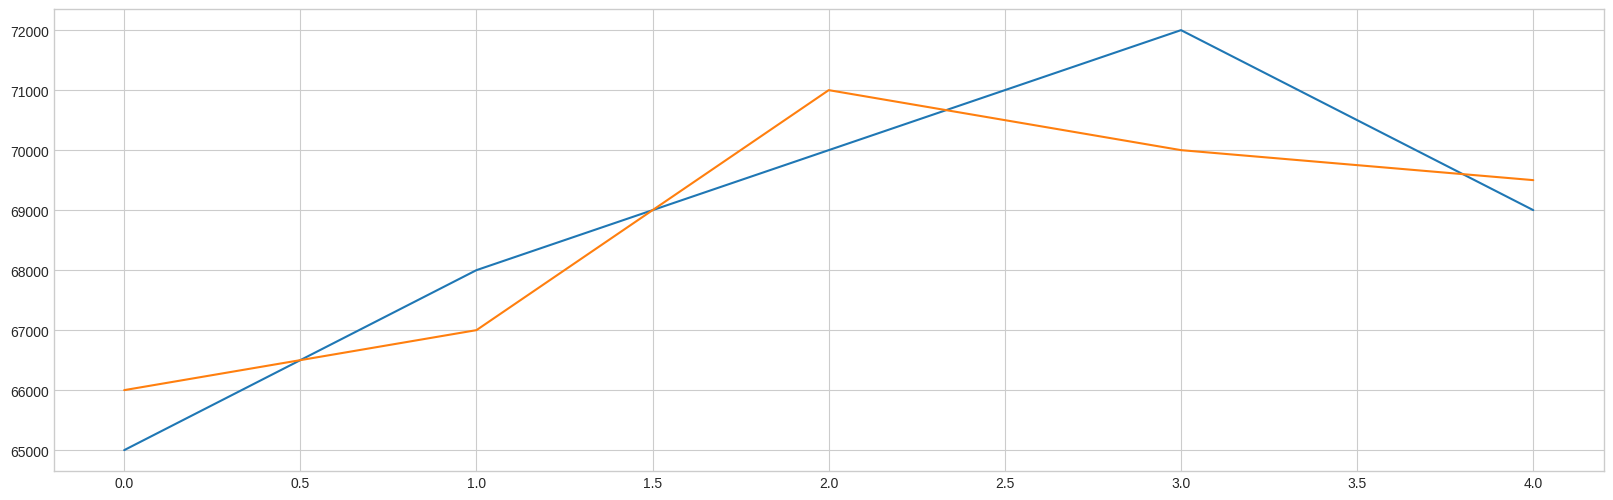

In [62]:
import matplotlib.pyplot as plt

actual = [65000, 68000, 70000, 72000, 69000]
predicted = [66000, 67000, 71000, 70000, 69500]

rmse, mae, mape = evaluate_forecast(
    actual,
    predicted,
    plot_title='Ballarat Daily Waste Forecast'
)

Model Selection

Optimum lag model

RMSE: 4235.231516694217
MAE: 2556.338623046875
MAPE: 2.157684367126692e+17


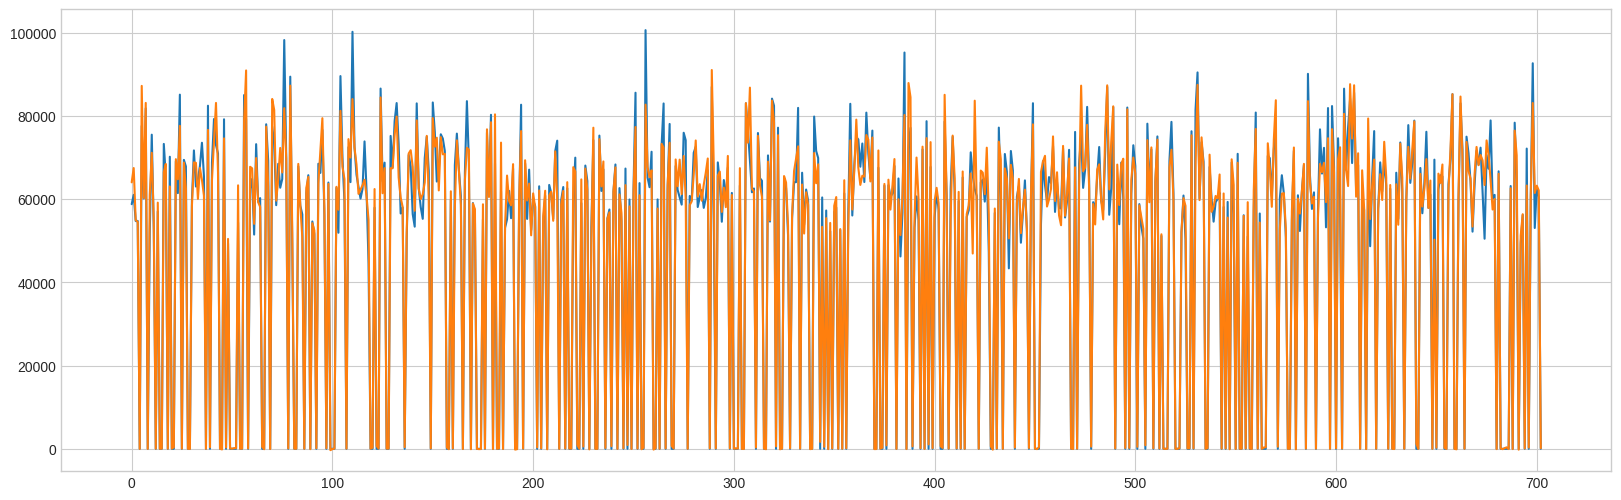

(4235.231516694217, 2556.338623046875, 2.157684367126692e+17)

In [63]:
df_temp = df.copy()

# Create lag features
for i in range(1, optimum_lag_model_params['lag_count'] + 1):
    df_temp['net_weight_kg_lag_{}'.format(i)] = df_temp['net_weight_kg'].shift(i)

df_temp = df_temp.dropna()

del df_temp['ticket_date']

# Split the dataset
X = df_temp.drop(['net_weight_kg'], axis=1)
y = df_temp['net_weight_kg'].tolist()

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0, shuffle=True)

model_optimum = xgboost.XGBRegressor(
    n_estimators=optimum_lag_model_params['estimator_count'],
    seed=0,
    max_depth=optimum_lag_model_params['max_depth'],
    subsample=optimum_lag_model_params['subsample'],
    eta=optimum_lag_model_params['eta']
)
model_optimum.fit(X_train, y_train)

y_pred = model_optimum.predict(X_test)

evaluate_forecast(y_test, y_pred)

In [64]:
# Check actual values in the evaluation set
y_test_array = np.asarray(y_test)

print("Number of test observations:", len(y_test_array))
print("Zero actual values:", np.sum(y_test_array == 0))
print("Negative actual values:", np.sum(y_test_array < 0))
print("Near-zero actual values:", np.sum(np.abs(y_test_array) < 1e-8))
print("Minimum actual value:", np.min(y_test_array))

Number of test observations: 703
Zero actual values: 214
Negative actual values: 0
Near-zero actual values: 214
Minimum actual value: 0.0


Minimum lag model

RMSE: 4235.231516694217
MAE: 2556.338623046875
MAPE: 2.157684367126692e+17


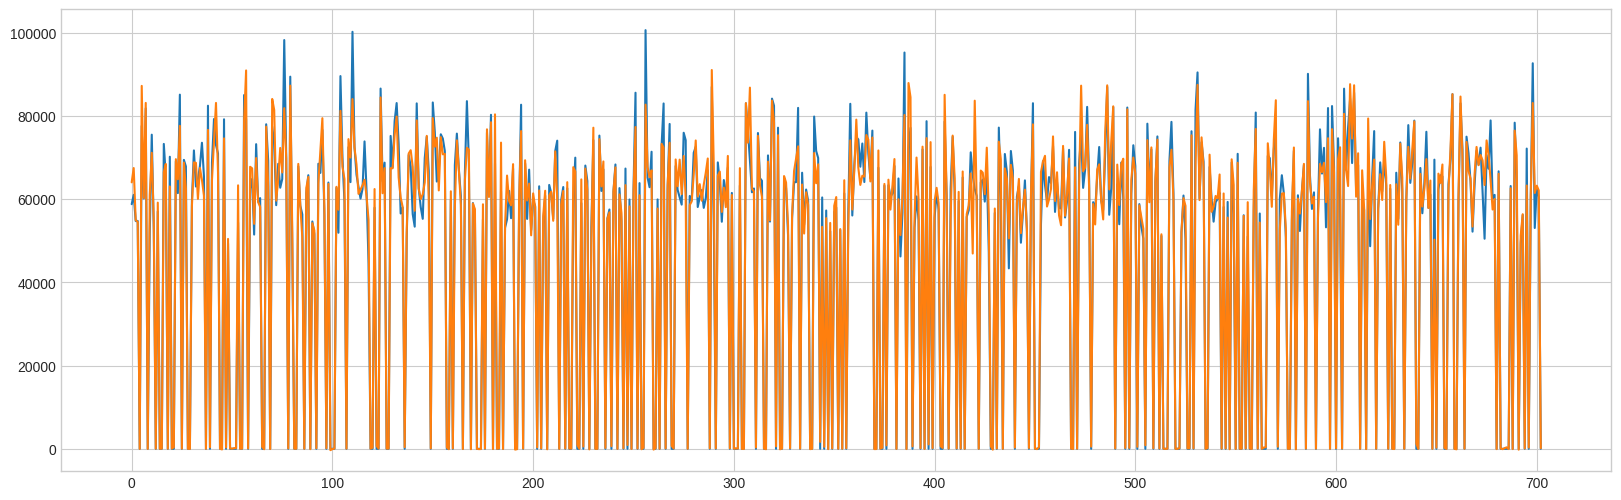

(4235.231516694217, 2556.338623046875, 2.157684367126692e+17)

In [65]:
df_temp = df.copy()

# Create lag features
for i in range(1, minimum_lag_model_params['lag_count'] + 1):
    df_temp['net_weight_kg_lag_{}'.format(i)] = df_temp['net_weight_kg'].shift(i)

df_temp = df_temp.dropna()

del df_temp['ticket_date']

# Split the dataset
X = df_temp.drop(['net_weight_kg'], axis=1)
y = df_temp['net_weight_kg'].tolist()

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0, shuffle=True)

model_minimum = xgboost.XGBRegressor(
    n_estimators=minimum_lag_model_params['estimator_count'],
    seed=0,
    max_depth=minimum_lag_model_params['max_depth'],
    subsample=minimum_lag_model_params['subsample'],
    eta=minimum_lag_model_params['eta']
)
model_minimum.fit(X_train, y_train)

y_pred = model_minimum.predict(X_test)

evaluate_forecast(y_test, y_pred)

In [66]:
# Impute data
df['predicted_net_weight_kg'] = np.nan
for index, row in df.iterrows():
    ticket_date = row['ticket_date']
    net_weight_kg = row['net_weight_kg']

    if not pd.notnull(row['net_weight_kg']):
        if index > optimum_lag_model_params['lag_count']:
            previous_values = df[index - optimum_lag_model_params['lag_count']:index]['net_weight_kg'].tolist()[::-1]
            column_list = []
            for i in range(1, optimum_lag_model_params['lag_count'] + 1):
                column_list.append('net_weight_kg_lag_{}'.format(i))

            previous_df = pd.DataFrame([previous_values], columns=column_list)
            current_value_pred = model_optimum.predict(previous_df)
        else:
            previous_values = df[index - minimum_lag_model_params['lag_count']:index]['net_weight_kg'].tolist()[::-1]
            column_list = []
            for i in range(1, minimum_lag_model_params['lag_count'] + 1):
                column_list.append('net_weight_kg_lag_{}'.format(i))

            previous_df = pd.DataFrame([previous_values], columns=column_list)
            current_value_pred = model_minimum.predict(previous_df)

        df.at[index,'net_weight_kg'] = current_value_pred
        df.at[index,'predicted_net_weight_kg'] = current_value_pred

In [67]:
print(f' imputed values: {df["predicted_net_weight_kg"].count()}')
print(f'Percentage of imputed values: {df["predicted_net_weight_kg"].count() / df["predicted_net_weight_kg"].isna().sum() * 100.0}')
print(f'Mean daily weight: {df["predicted_net_weight_kg"].mean()}')
print(f'SD daily weight: {df["predicted_net_weight_kg"].std()}')

 imputed values: 46
Percentage of imputed values: 1.158398388315286
Mean daily weight: 70327.19038722826
SD daily weight: 10172.96056390008


## Actual versus predicted daily waste weight for each year from 2001 to 2011

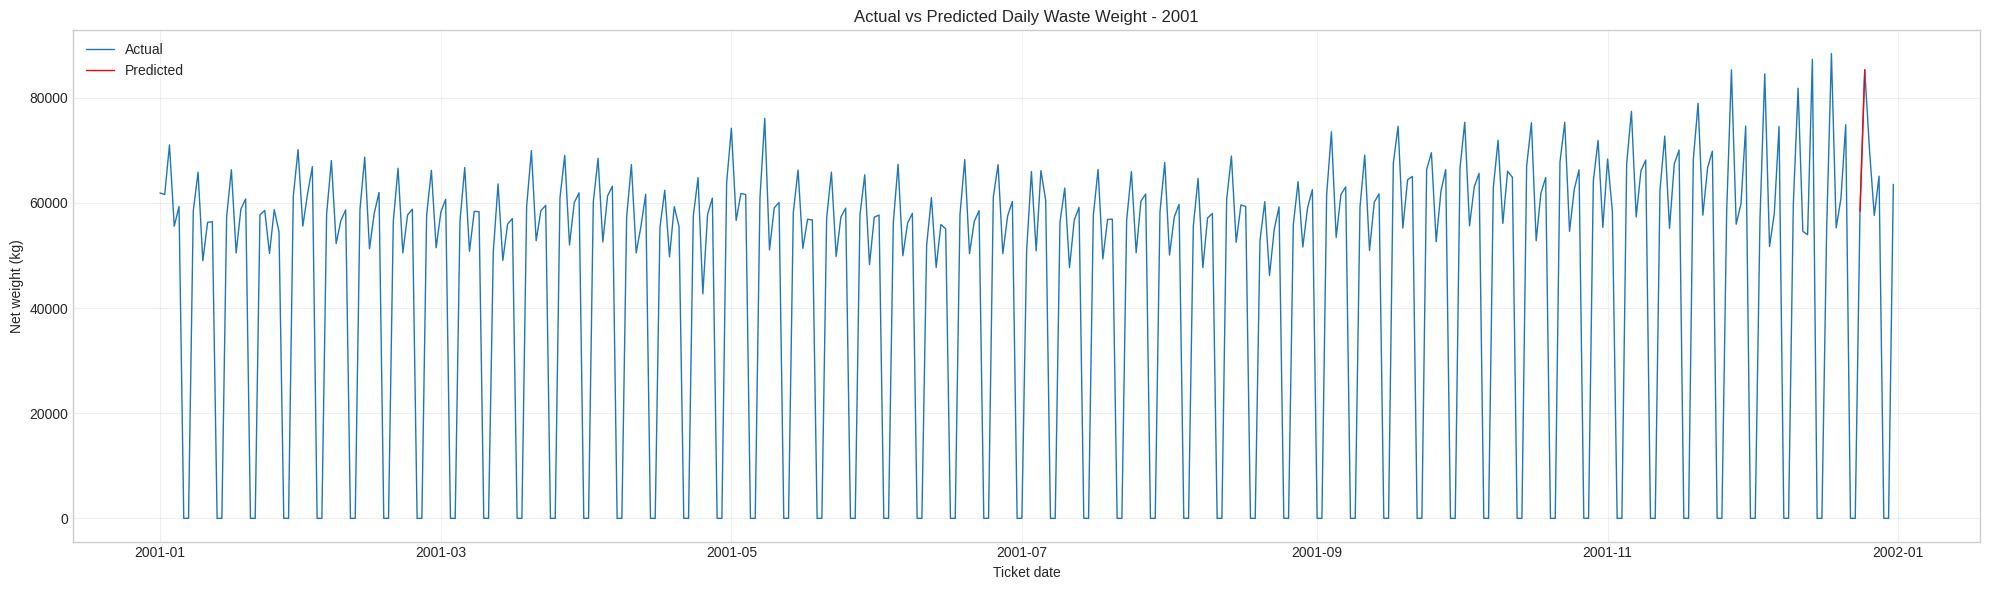

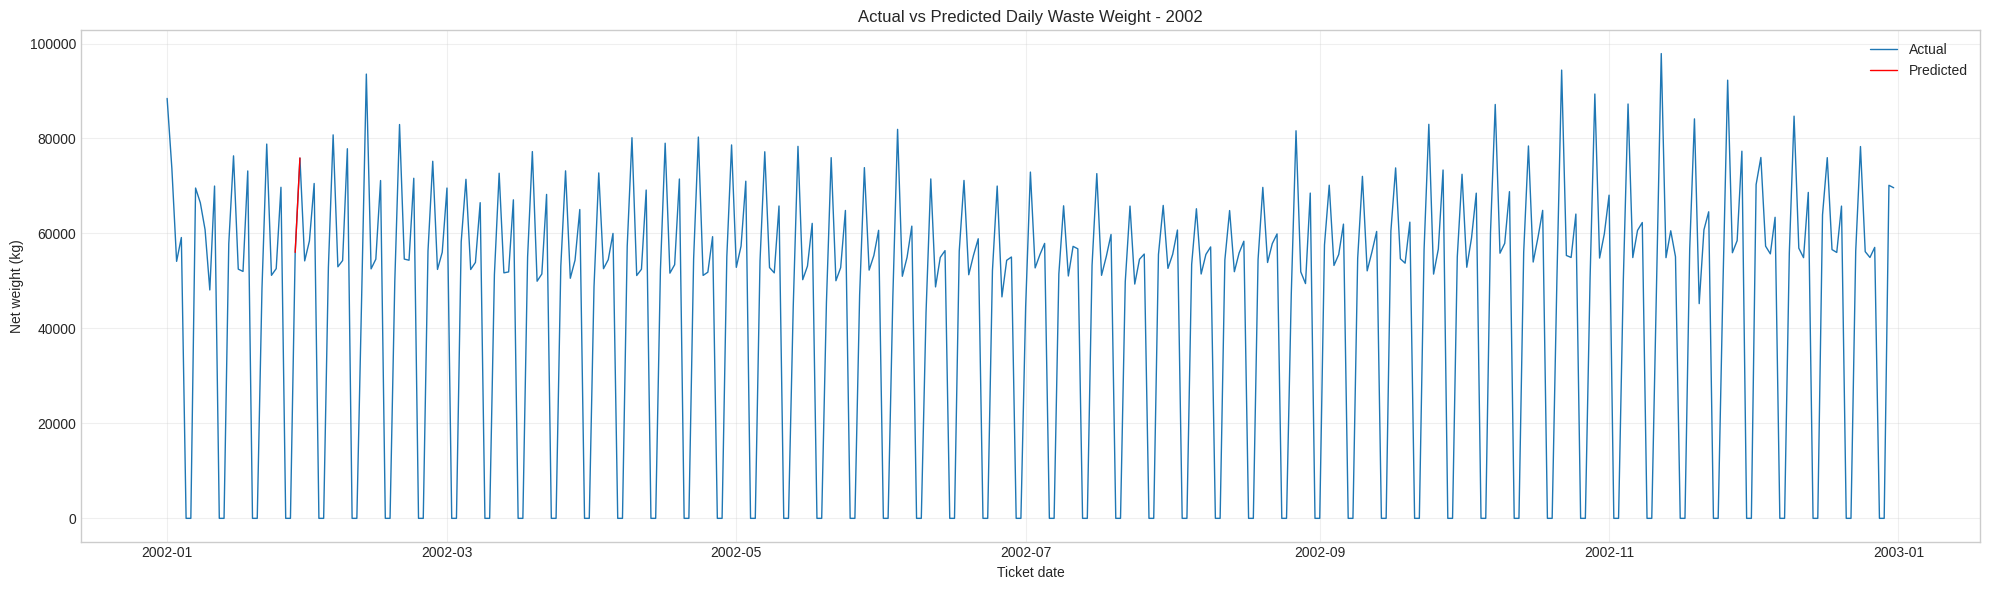

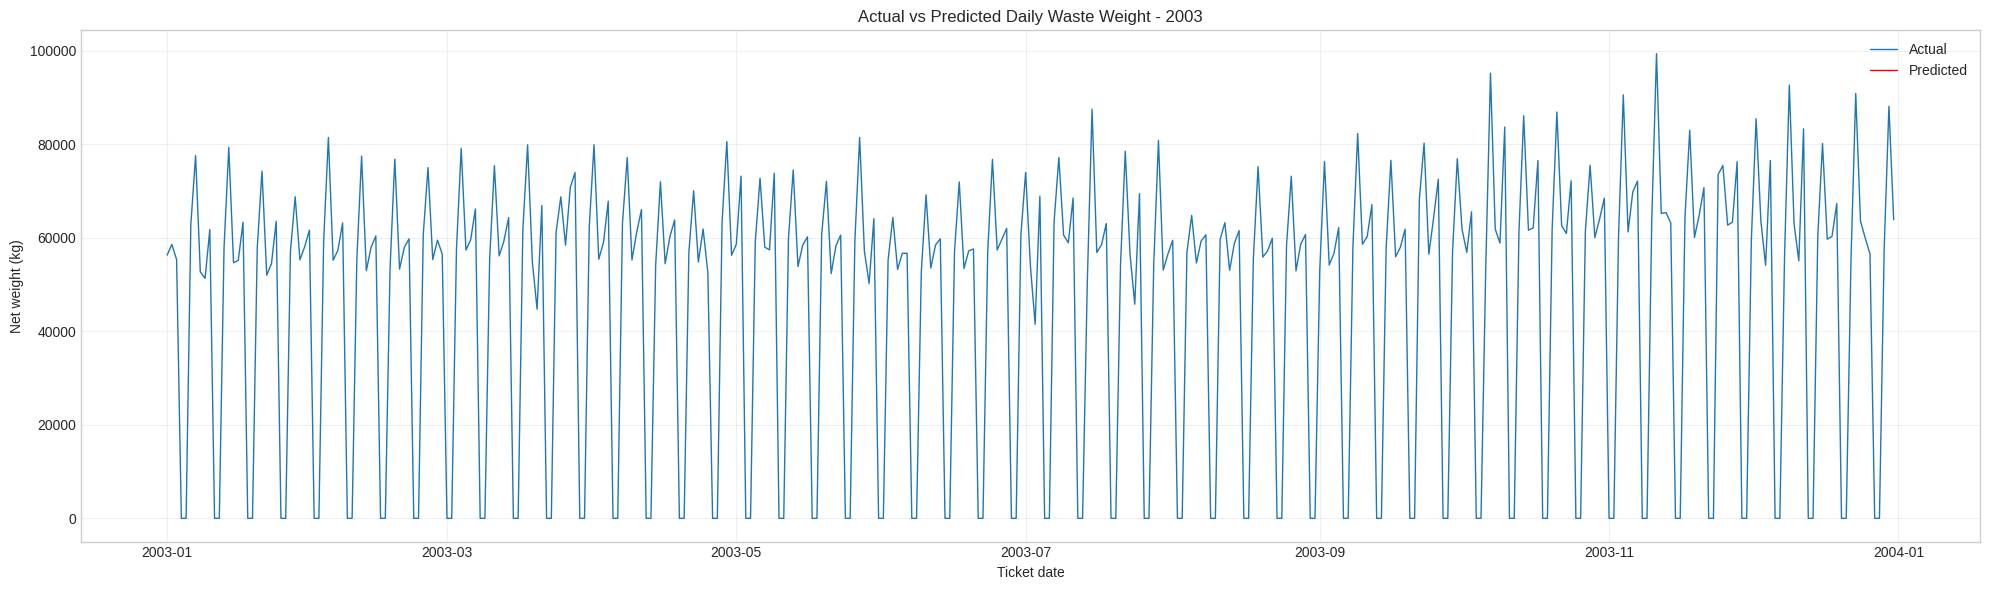

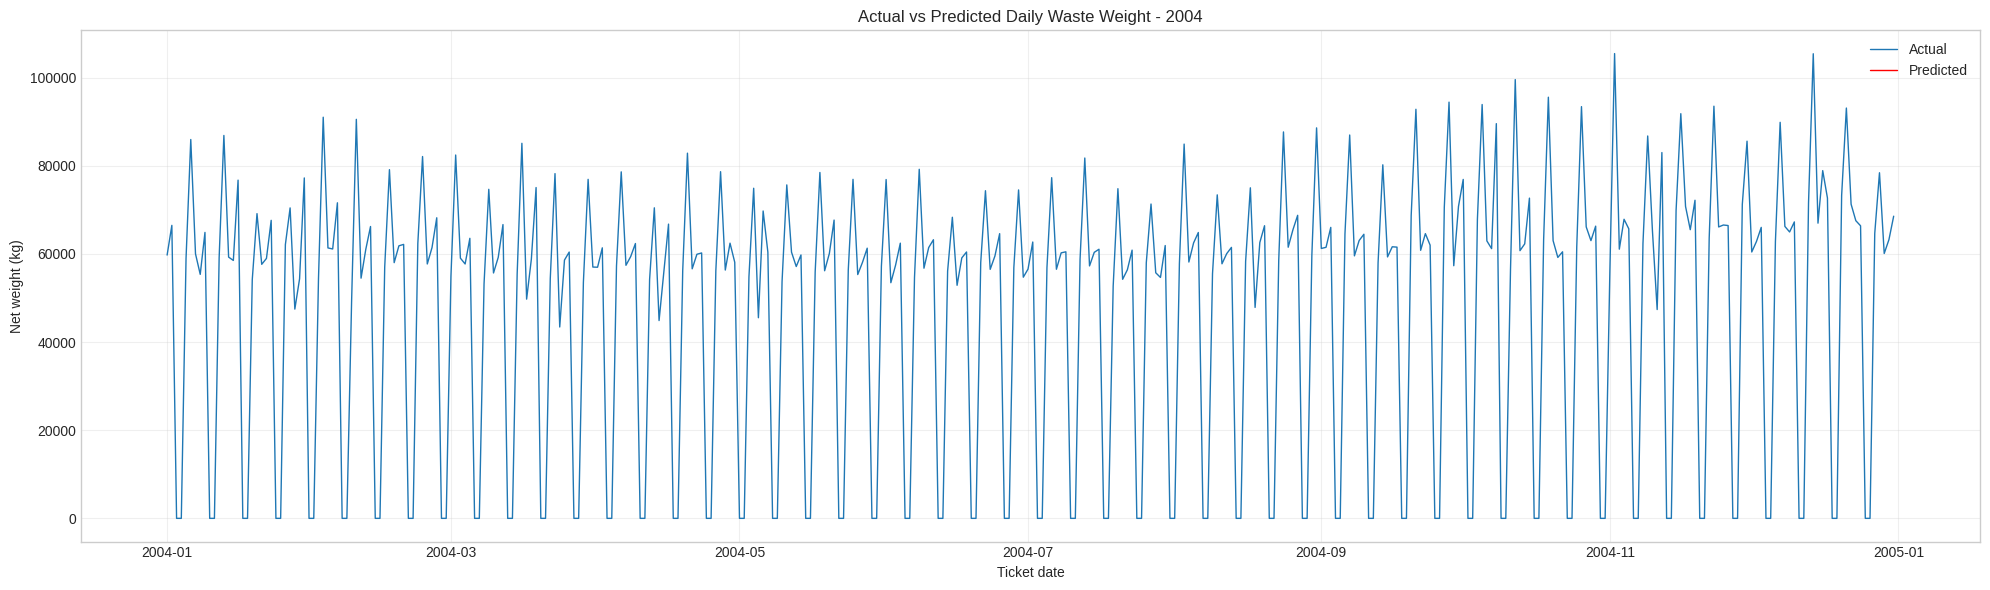

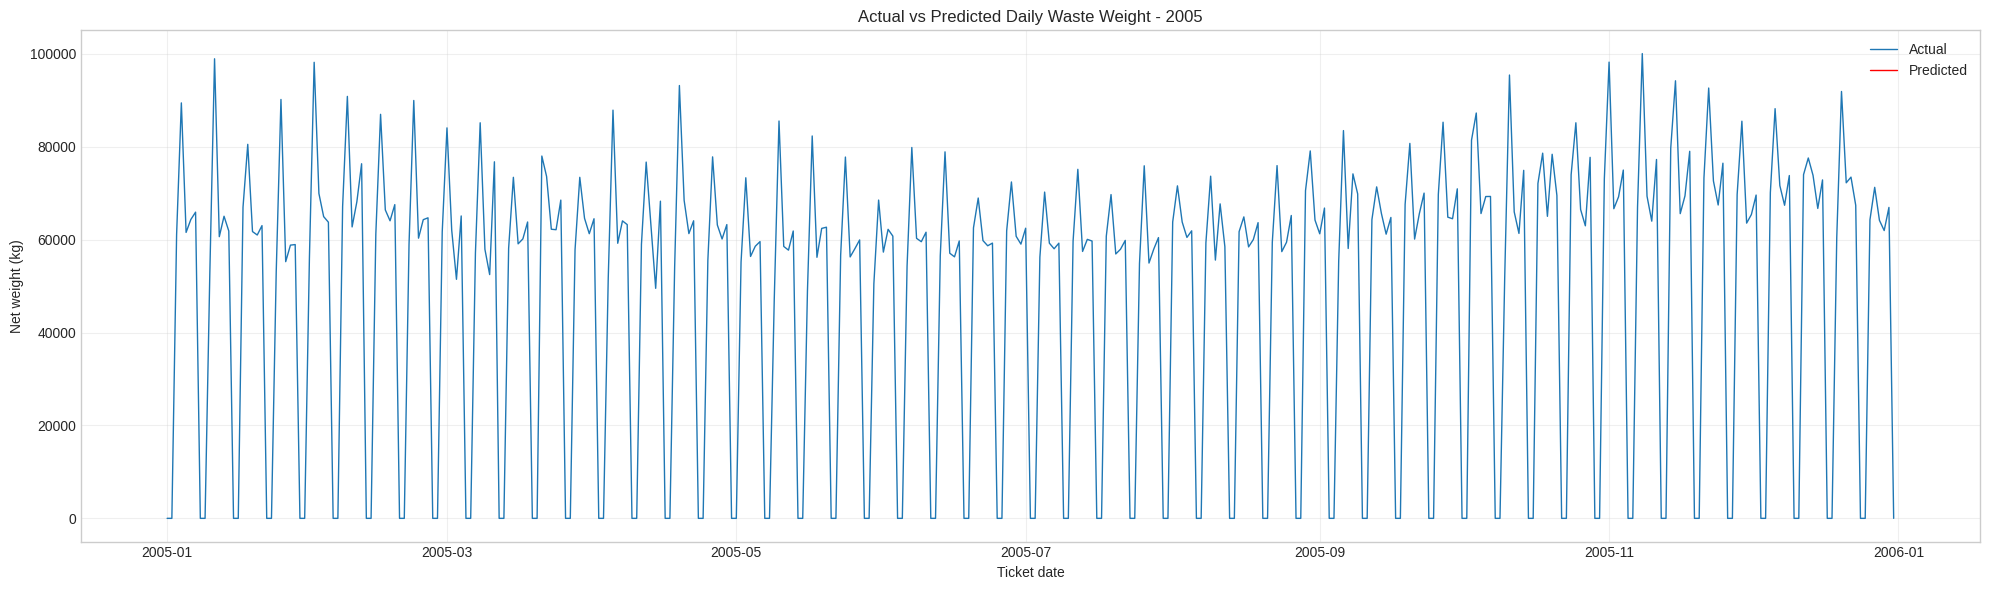

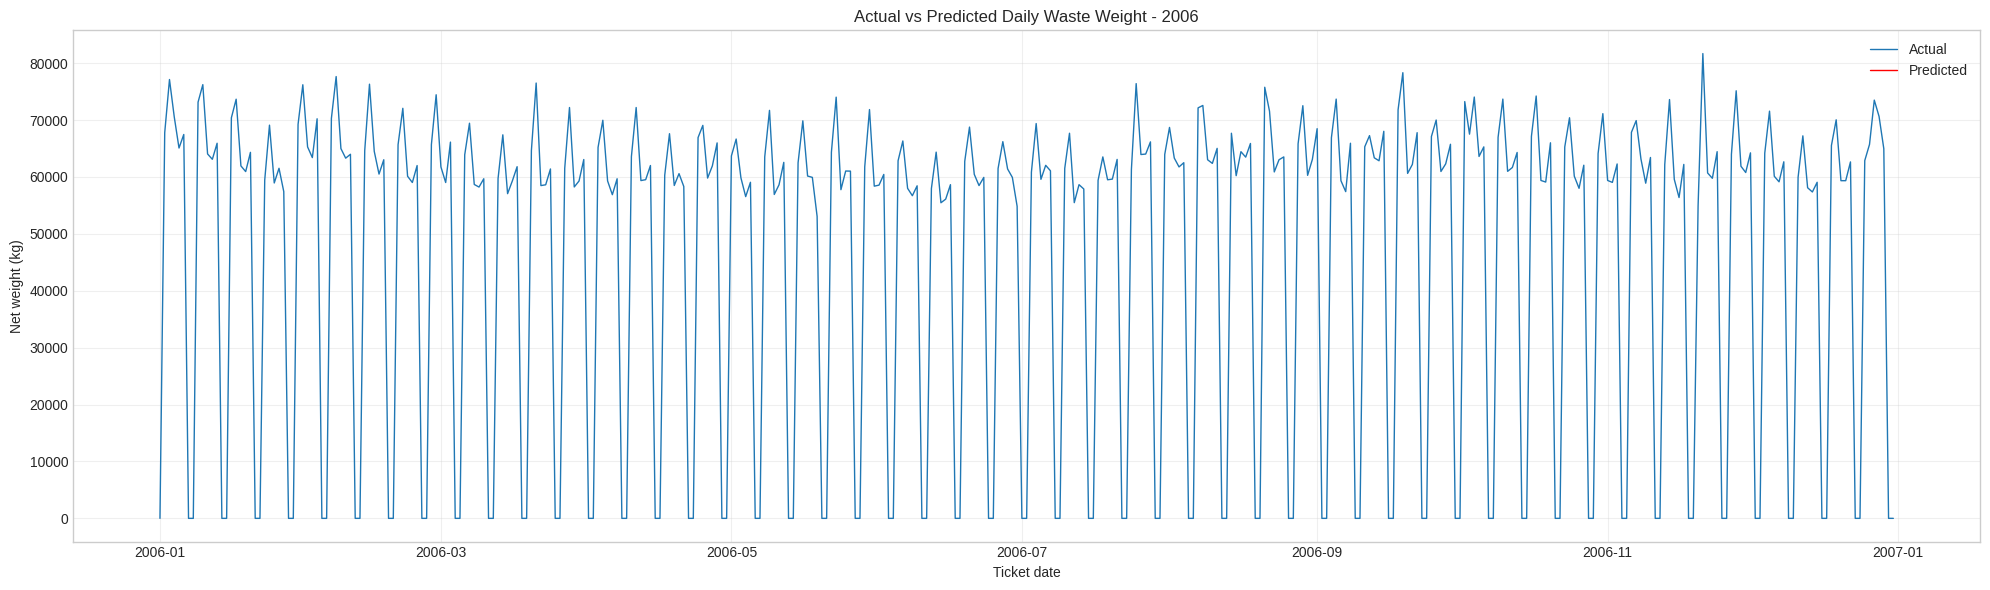

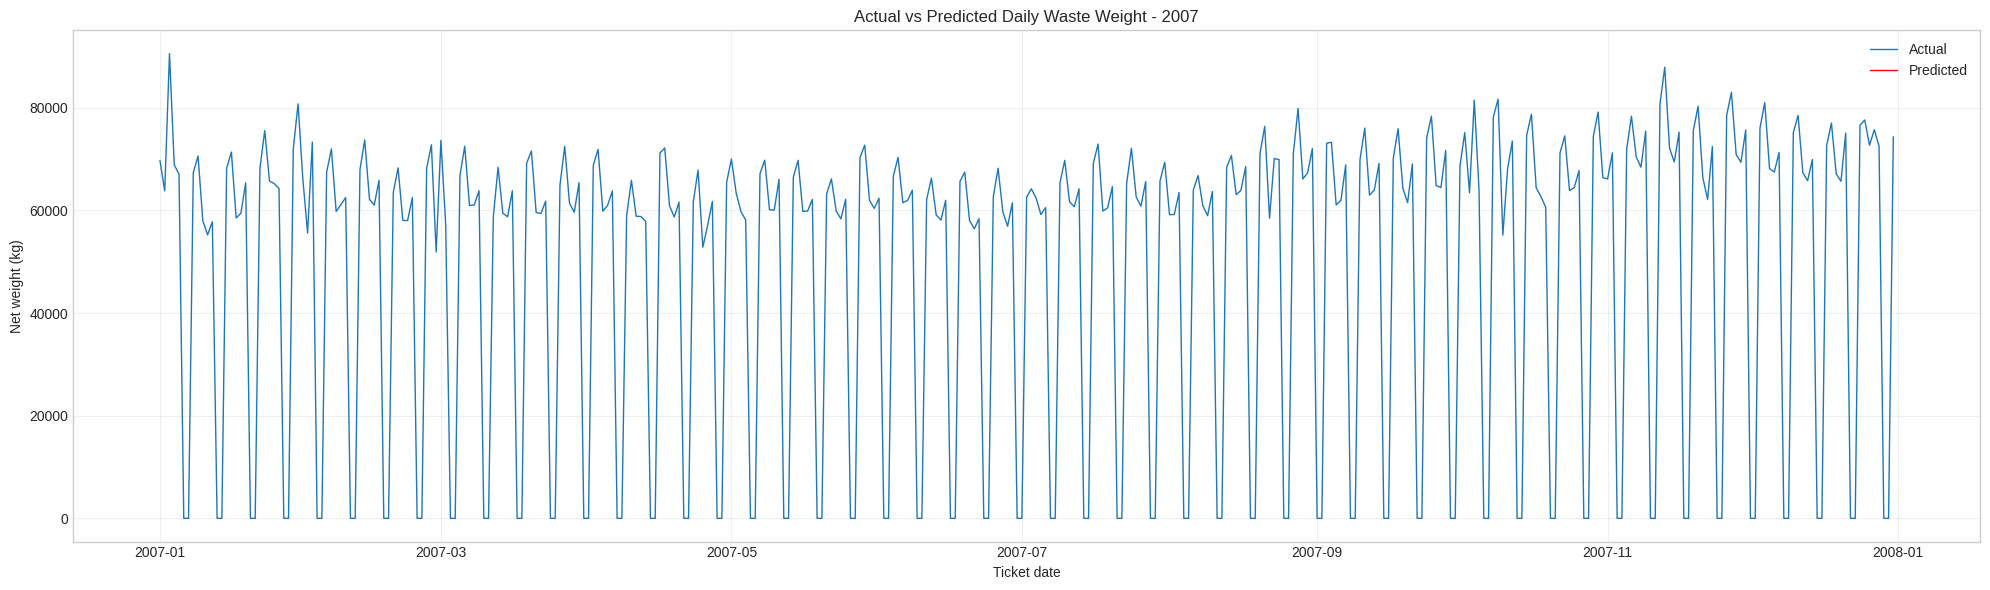

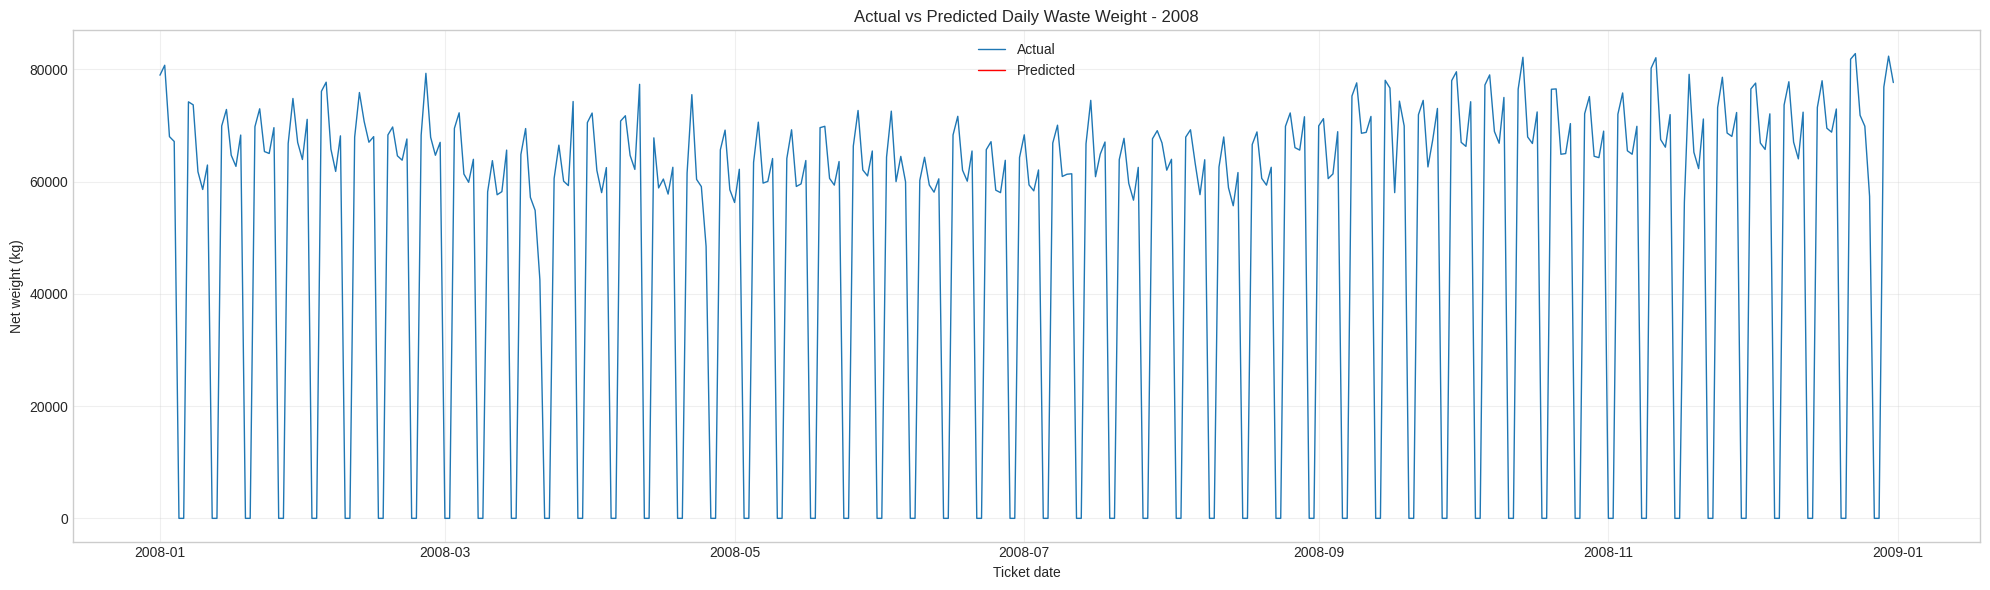

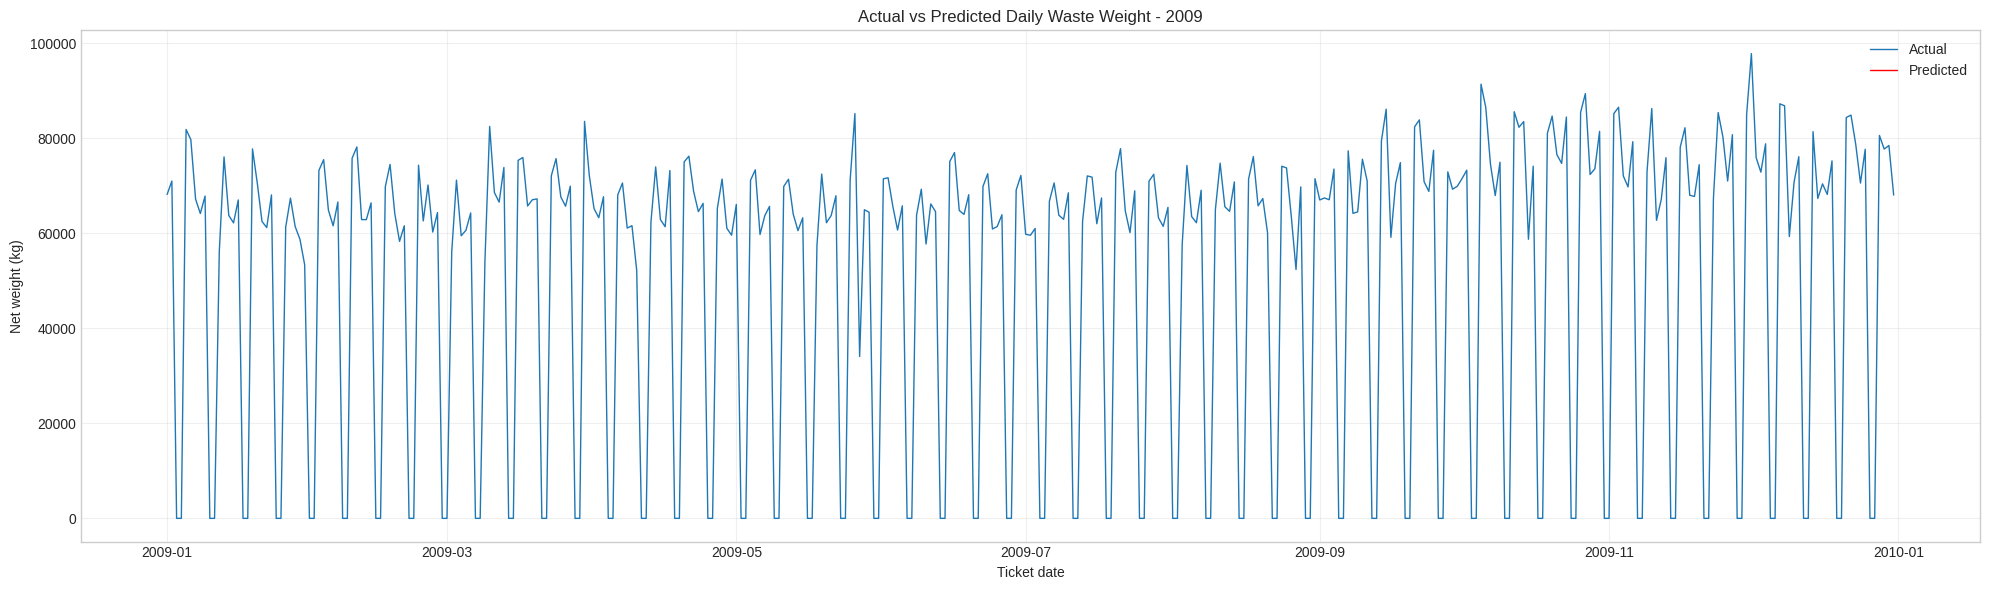

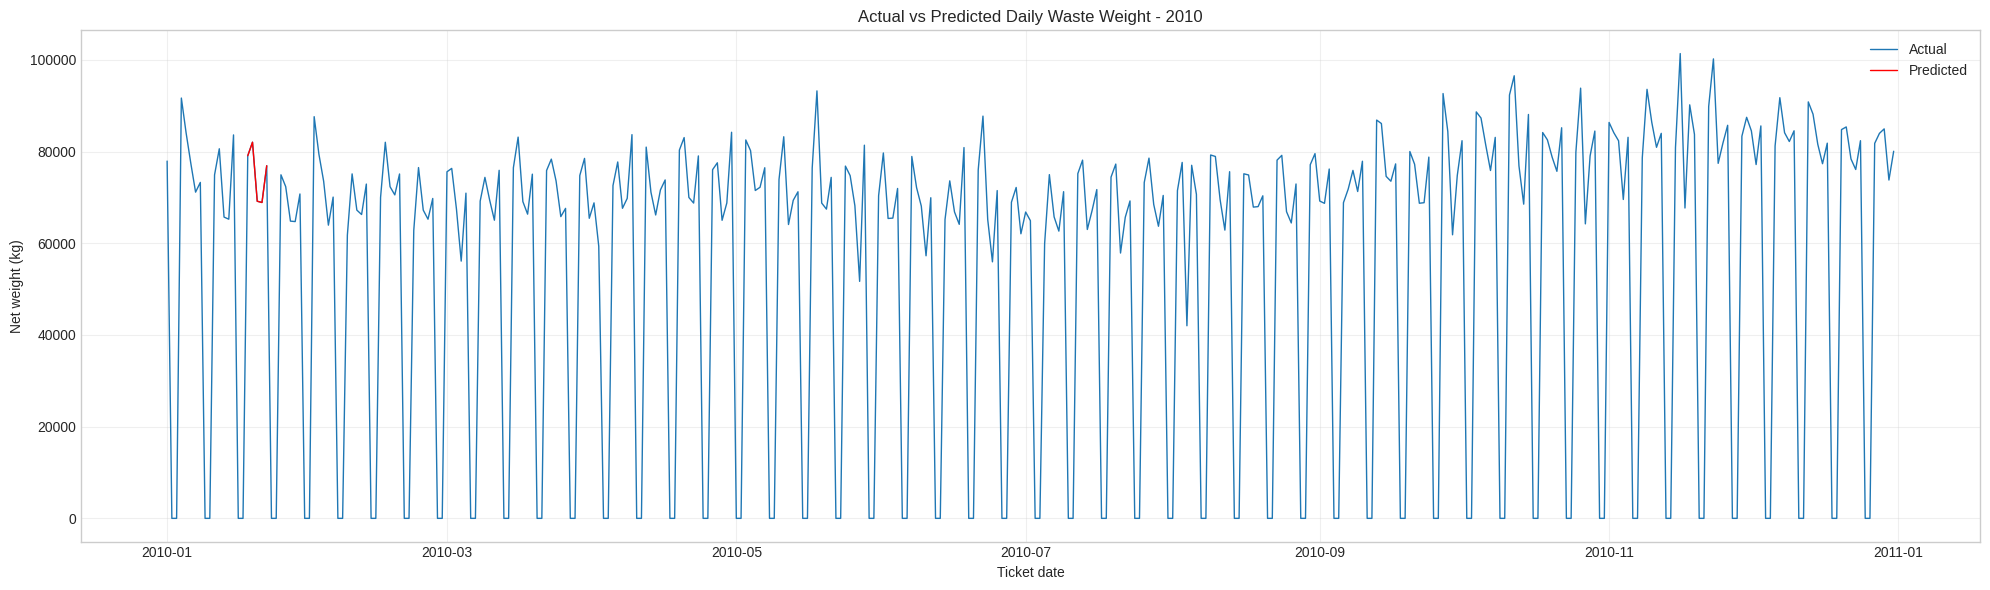

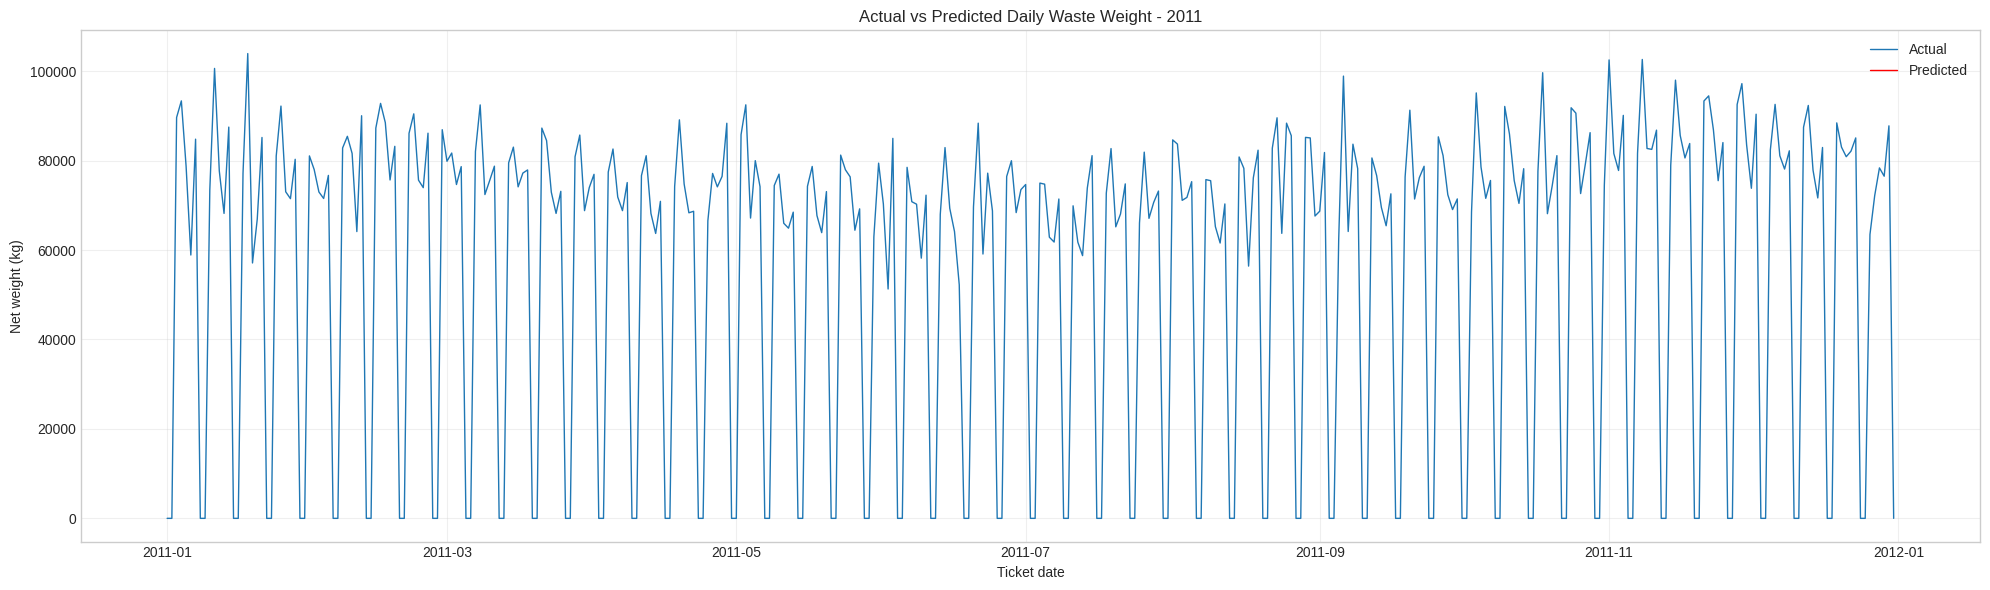

In [68]:
for year in range(2001, 2012):

    df_year = df[df['ticket_date'].dt.year == year].copy()

    if df_year.empty:
        print(f"No data available for {year}")
        continue

    plt.figure(figsize=(20, 6), dpi=100)

    # Actual waste weight
    plt.plot(
        df_year['ticket_date'],
        df_year['net_weight_kg'],
        label='Actual',
        linewidth=1
    )

    # Predicted waste weight
    plt.plot(
        df_year['ticket_date'],
        df_year['predicted_net_weight_kg'],
        color='red',
        label='Predicted',
        linewidth=1
    )

    plt.title(f'Actual vs Predicted Daily Waste Weight - {year}')
    plt.xlabel('Ticket date')
    plt.ylabel('Net weight (kg)')
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

## Actual and Predicted Daily waste Data

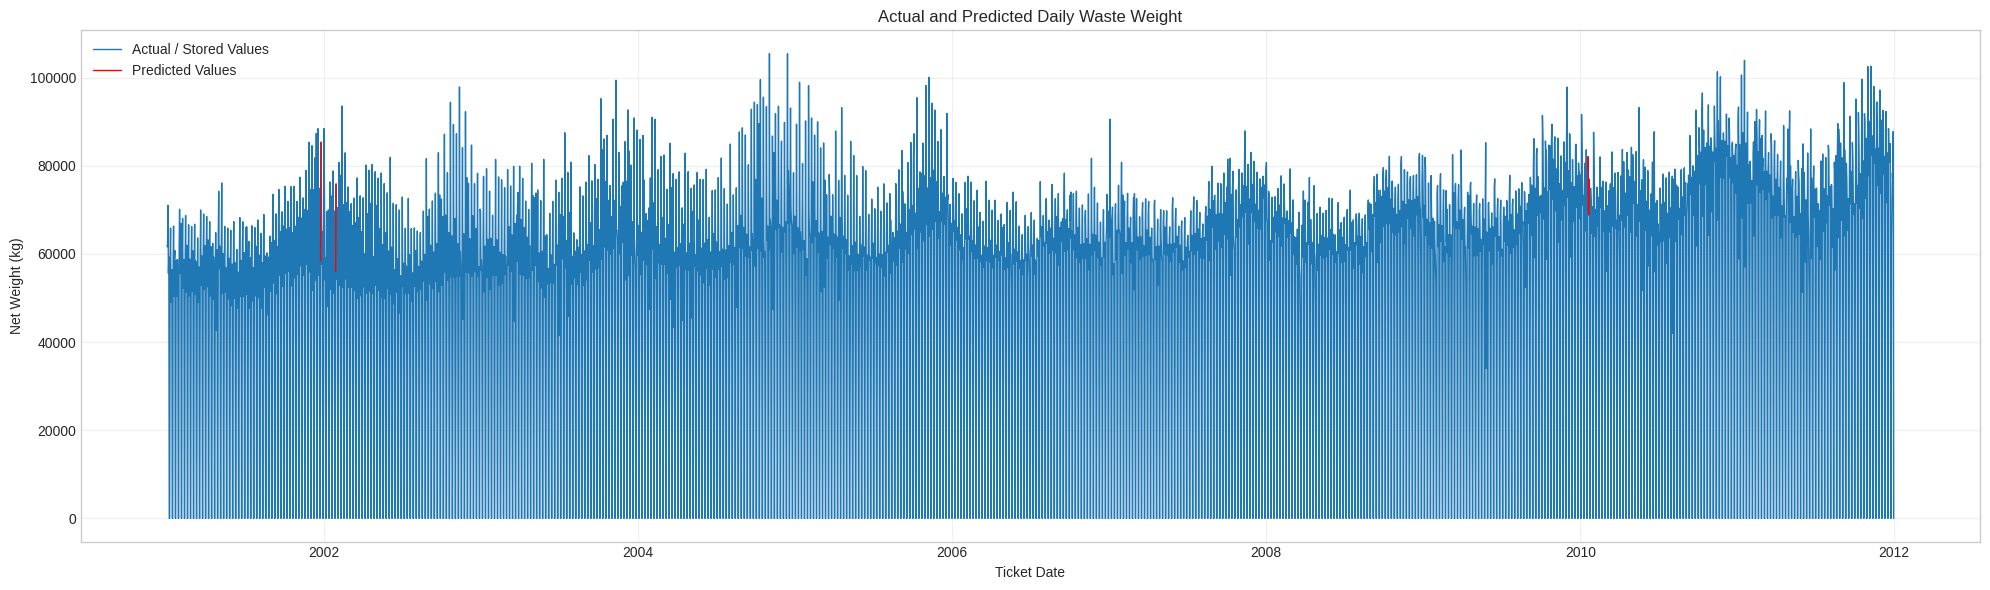

In [69]:
plt.figure(figsize=(20, 6))

plt.plot(
    df['ticket_date'],
    df['net_weight_kg'],
    label='Actual / Stored Values',
    linewidth=1
)

plt.plot(
    df['ticket_date'],
    df['predicted_net_weight_kg'],
    color='red',
    label='Predicted Values',
    linewidth=1
)

plt.title('Actual and Predicted Daily Waste Weight')
plt.xlabel('Ticket Date')
plt.ylabel('Net Weight (kg)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [70]:
df_backup = df.copy()
del df['predicted_net_weight_kg']

In [72]:
DAILY_WASTE_OUTPUT_DATA_FILE_PATH = '/content/daily_waste_output_Ballarat.csv'

df.to_csv(DAILY_WASTE_OUTPUT_DATA_FILE_PATH, index=False)

print("File saved successfully:", DAILY_WASTE_OUTPUT_DATA_FILE_PATH)

File saved successfully: /content/daily_waste_output_Ballarat.csv
